<a href="https://colab.research.google.com/github/twobombs/thereminq-examples/blob/main/devices/nighthawk-r3/nighthawk_qrack_colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Nighthawk Qrack (`nighthawk_qrack.py`) — Google Colab Setup & Verification

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/twobombs/thereminq-examples/blob/main/devices/nighthawk-r3/nighthawk_qrack_colab.ipynb)

This notebook sets up and verifies [`nighthawk_qrack.py`](https://github.com/twobombs/thereminq-examples/blob/main/devices/nighthawk-r3/nighthawk_qrack.py), the consolidated clean-qubit **PyQrack** companion to `arXiv:2609.28657` (random-circuit sampling on IBM Nighthawk r2 / `ibm_phoenix`, 61 qubits) and IBM Nighthawk r3 / multi-chip cloverfield simulations.

### Workflow
1. **Install dependencies** (pinned `pyqrack`, `qiskit`, `ortools`, `scipy`, `matplotlib`, `numpy`; the Qrack runtime libraries `libclblast1`, `libopenblas0`, `ocl-icd-libopencl1`; and OpenCL via NVIDIA ICD on GPU runtimes or `pocl-opencl-icd` on CPU runtimes).
2. **Clone repositories** (`twobombs/thereminq-examples` and `BlueQubitDev/rcs-nighthawk`).
3. **Verify circuits & release data** (`verify` and `seamgap`).
4. **Run the self-test suites** (`selftest`, `ghz selftest`, `field selftest`, `erepr selftest`, `lab --selftest`).
5. **Dimension ACE patches from available system RAM / OpenCL stack memory** and run Nighthawk r2/r3 & Cloverfield plans and quick simulations (`aceplan`, `field plan`, `run`, `field run`).

## 1. Environment & Dependency Setup

Run the cell below to install Python packages (`pyqrack` pinned to `PYQRACK_VERSION`, `qiskit`, `ortools`, `scipy`, `matplotlib`) and the shared libraries the PyQrack wheel links against (`libclblast1`, `libopenblas0`, `ocl-icd-libopencl1`), then configure OpenCL (NVIDIA OpenCL ICD when a GPU is detected, or `pocl-opencl-icd` when running on CPU).

Before importing PyQrack the cell runs `ldd` on `libqrack_pinvoke.so` and stops with the names of any missing libraries. PyQrack's own import error only reports its last fallback path (`/usr/lib/qrack/libqrack_pinvoke.so`), which hides the real cause.

| Setting | Default | Meaning |
|---|---|---|
| `PYQRACK_VERSION` | `2.30.6` | PyQrack release the self-tests in this notebook last passed on; bump after a clean run |
| `QRACK_LIB_PATH` | `/usr/local/lib/qrack/libqrack_pinvoke.so` | used instead of the wheel's library when present (same convention as `nighthawk_qrack.py`) |

In [1]:
import importlib.util
import os
import shutil
import subprocess
import sys
from pathlib import Path

PYQRACK_VERSION = "2.30.6"   # last release this notebook's self-tests passed on; bump after a clean run

# Same convention as nighthawk_qrack.py: a locally built Qrack takes precedence over the wheel's library
QRACK_LIB_PATH = "/usr/local/lib/qrack/libqrack_pinvoke.so"
if os.path.exists(QRACK_LIB_PATH):
    os.environ["PYQRACK_SHARED_LIB_PATH"] = QRACK_LIB_PATH

# Install required Python packages
subprocess.check_call([
    sys.executable, "-m", "pip", "install", "-q",
    f"pyqrack=={PYQRACK_VERSION}", "qiskit", "ortools", "scipy", "matplotlib", "numpy"
])

# Shared libraries the PyQrack wheel's libqrack_pinvoke.so links against, needed on GPU and CPU runtimes alike
QRACK_RUNTIME_PKGS = ["ocl-icd-libopencl1", "libclblast1", "libopenblas0", "clinfo"]

# Check for GPU via nvidia-smi; if no GPU is detected, install PoCL (pocl-opencl-icd)
has_nvidia = shutil.which("nvidia-smi") is not None and subprocess.call(
    ["nvidia-smi"], stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL
) == 0

subprocess.check_call(["apt-get", "update", "-qq"])
if has_nvidia:
    print("GPU detected via nvidia-smi; configuring NVIDIA OpenCL ICD...")
    subprocess.check_call(["apt-get", "install", "-y", "-qq", *QRACK_RUNTIME_PKGS])
    os.makedirs("/etc/OpenCL/vendors", exist_ok=True)
    nv_icd = "/etc/OpenCL/vendors/nvidia.icd"
    if not os.path.exists(nv_icd):
        # Full path when the driver library is found (Colab keeps it in /usr/lib64-nvidia), else the soname
        nv_lib = next((str(p) for d in ("/usr/lib64-nvidia", "/usr/lib/x86_64-linux-gnu", "/usr/lib64")
                       for p in [Path(d) / "libnvidia-opencl.so.1"] if p.exists()), "libnvidia-opencl.so.1")
        with open(nv_icd, "w") as f:
            f.write(nv_lib + "\n")
else:
    print("No GPU detected; installing PoCL (pocl-opencl-icd) for CPU OpenCL support...")
    subprocess.check_call(["apt-get", "install", "-y", "-qq", "pocl-opencl-icd", *QRACK_RUNTIME_PKGS])

print("\nOpenCL devices (clinfo -l):")
clinfo_out = subprocess.run(["clinfo", "-l"], capture_output=True, text=True).stdout
print(clinfo_out)
if has_nvidia and "nvidia" not in clinfo_out.lower():
    print("WARNING: nvidia-smi sees a GPU but OpenCL lists no NVIDIA platform; check /etc/OpenCL/vendors/nvidia.icd")

# Resolve libqrack_pinvoke.so's dependencies before importing PyQrack, so a missing library is named
_spec = importlib.util.find_spec("pyqrack")
_wheel_lib = Path(_spec.submodule_search_locations[0]) / "qrack_system" / "qrack_lib" / "libqrack_pinvoke.so"
qrack_lib = Path(QRACK_LIB_PATH) if os.path.exists(QRACK_LIB_PATH) else _wheel_lib
ldd_out = subprocess.run(["ldd", str(qrack_lib)], capture_output=True, text=True).stdout
missing = sorted({line.split("=>")[0].strip() for line in ldd_out.splitlines() if "not found" in line})
if missing:
    raise RuntimeError(f"{qrack_lib} cannot load; missing shared libraries: {', '.join(missing)}. "
                       f"Install the packages that provide them (apt-get install {' '.join(QRACK_RUNTIME_PKGS)}).")
print(f"Qrack library: {qrack_lib} (all dependencies resolved)")

import pyqrack
from importlib.metadata import version
print(f"\nPyQrack version: {version('pyqrack')}")
print(f"Qiskit version:  {version('qiskit')}")
print(f"OR-Tools version: {version('ortools')}")

GPU detected via nvidia-smi; configuring NVIDIA OpenCL ICD...

OpenCL devices (clinfo -l):
Platform #0: NVIDIA CUDA
 `-- Device #0: NVIDIA L4

Qrack library: /usr/local/lib/python3.13/dist-packages/pyqrack/qrack_system/qrack_lib/libqrack_pinvoke.so (all dependencies resolved)

PyQrack version: 2.30.6
Qiskit version:  2.6.2
OR-Tools version: 9.15.6755


## 2. Clone Repositories & Set Working Directory

This cell clones `twobombs/thereminq-examples` (if not already present), moves into `devices/nighthawk-r3`, and clones the `BlueQubitDev/rcs-nighthawk` dataset next to `nighthawk_qrack.py`.

In [2]:
import os
import re
import shlex
import subprocess
import threading
import time
from pathlib import Path

if not Path("nighthawk_qrack.py").is_file():
    if not Path("thereminq-examples").is_dir():
        !git clone --depth 1 https://github.com/twobombs/thereminq-examples.git
    %cd thereminq-examples/devices/nighthawk-r3

if not Path("rcs-nighthawk/data/layout.json").is_file():
    !git clone --depth 1 https://github.com/BlueQubitDev/rcs-nighthawk.git rcs-nighthawk

os.environ["NIGHTHAWK_REPO"] = str(Path("rcs-nighthawk").resolve())
print("Working directory:", Path.cwd())
print("NIGHTHAWK_REPO:   ", os.environ["NIGHTHAWK_REPO"])

# Qrack prints this once per process that starts with OpenCL hidden (CPU chip workers, the loom); see run_logged
_HIDDEN_OCL_LINE = "No platforms found. Check OpenCL installation!"


def run_logged(cmd, cwd=None, timeout=None, echo=True, quiet=False):
    """Run a command and stream its output into the notebook, so it is saved with the cell.
    (A plain subprocess.run writes to the kernel's file descriptors, which Colab does not keep.)
    Collapses Qrack's per-process 'No platforms found' line from OpenCL-hidden workers into one count.
    Returns dict(rc, out, seconds, timed_out); raises CalledProcessError on a non-zero exit."""
    if echo:
        print(f"$ {shlex.join(cmd)}", flush=True)
    t0 = time.time()
    p = subprocess.Popen(cmd, cwd=cwd, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True, bufsize=1,
                         start_new_session=True)
    lines, hidden, expired = [], 0, []

    def _expire():
        expired.append(True)
        try:
            os.killpg(p.pid, 9)        # the run's chip workers and loom too, not only the launcher
        except OSError:
            pass

    timer = threading.Timer(timeout, _expire) if timeout else None
    if timer:
        timer.start()
    try:
        for line in p.stdout:
            if line.strip() == _HIDDEN_OCL_LINE:
                hidden += 1
                continue
            lines.append(line)
            if not quiet:
                print(line, end="", flush=True)
        p.wait()
    except KeyboardInterrupt:
        _expire()
        raise
    finally:
        if timer:
            timer.cancel()
    timed_out = bool(expired)
    secs = time.time() - t0
    if timed_out:
        print(f"TIMEOUT after {timeout:g} s: stopped")
    if hidden and not quiet:
        print(f"({hidden} x '{_HIDDEN_OCL_LINE}' from OpenCL-hidden worker processes, expected)")
    out = "".join(lines)
    if p.returncode and not timed_out:
        if quiet:
            print(out[-4000:])
        raise subprocess.CalledProcessError(p.returncode, cmd, out)
    return dict(rc=p.returncode, out=out, seconds=secs, timed_out=timed_out)


def failed_points(out: str) -> str:
    """'' when a run finished all its points, else the run's own failure line (a chip worker that exits is
    retried once; points that fail twice go to <out>.failed.json and the run still exits 0)."""
    m = re.search(r"^# (\d+ point\(s\) (?:failed twice|marked failed).*)$", out, re.M)
    return m.group(1) if m else ""


Cloning into 'thereminq-examples'...
remote: Enumerating objects: 821, done.
remote: Counting objects: 100% (821/821), done.
remote: Compressing objects: 100% (681/681), done.
remote: Total 821 (delta 144), reused 698 (delta 128), pack-reused 0 (from 0)
Receiving objects: 100% (821/821), 182.47 MiB | 19.84 MiB/s, done.
Resolving deltas: 100% (144/144), done.
/content/thereminq-examples/devices/nighthawk-r3
Cloning into 'rcs-nighthawk'...
remote: Enumerating objects: 588, done.
remote: Counting objects: 100% (588/588), done.
remote: Compressing objects: 100% (144/144), done.
remote: Total 588 (delta 442), reused 579 (delta 442), pack-reused 0 (from 0)
Receiving objects: 100% (588/588), 39.31 MiB | 19.99 MiB/s, done.
Resolving deltas: 100% (442/442), done.
Working directory: /content/thereminq-examples/devices/nighthawk-r3
NIGHTHAWK_REPO:    /content/thereminq-examples/devices/nighthawk-r3/rcs-nighthawk


## 3. Circuit & Release Data Verification (`verify` & `seamgap`)

- `verify` regenerates all 233 circuits from `data/layout.json` and checks them gate-for-gate against `data/circuits/*.qasm`.
- `seamgap` runs the data-only analysis of CZ counts and fidelity vs. depth fits on the released dataset.

In [3]:
!python3 nighthawk_qrack.py verify --repo rcs-nighthawk
!python3 nighthawk_qrack.py seamgap --repo rcs-nighthawk

232 identical, 0 different (angle tol 1e-09 rad)
== CZ counts (mean [min-max]); gaps relative to the sampled full circuit ==
depth	full	mirror	K3	K4	full-mirror	full-K3
4	102[102-102]	94[94-94]	-	-	8 (7.8%)	-
6	-	150[150-150]	-	-	-	-
8	204[204-204]	190[190-190]	-	-	14 (6.9%)	-
10	-	232[232-232]	-	-	-	-
12	306[306-306]	264[264-264]	-	-	42 (13.7%)	-
14	-	312[312-312]	-	-	-	-
16	408[408-408]	348[348-348]	-	-	60 (14.7%)	-
18	-	398[398-398]	-	-	-	-
20	510[510-510]	442[442-442]	444[440-450]	401[395-415]	68 (13.3%)	66 (12.9%)
24	612[612-612]	532[532-532]	533[528-540]	481[474-498]	80 (13.1%)	79 (12.9%)
28	714[714-714]	616[616-616]	622[616-630]	561[553-581]	98 (13.7%)	92 (12.9%)
32	816[816-816]	706[706-706]	710[704-720]	642[632-664]	110 (13.5%)	106 (12.9%)
36	918[918-918]	802[802-802]	799[792-810]	722[711-747]	116 (12.6%)	119 (12.9%)
40	1020[1020-1020]	888[888-888]	888[880-900]	802[790-830]	132 (12.9%)	132 (12.9%)

== fit F(d) = 0.3257 x 0.8717^d ==
at d=36: 2.321e-03 (headline);  at gate-count

## 4. Self-Test Suites

Run the built-in self-tests across all command groups to confirm exactness, angle conventions, Pauli twirling, XEB scoring, CP-SAT layout search, VQE, Shor-9, QrackBridge, GHZ, Cloverfield loom, ER=EPR, and the Configuration Lab.

In [4]:
# Main self-test suite (14 checks: circuit regeneration, Haar u_angles, exact mirror, Pauli twirl,
# ideal patch XEB, hardware counts XEB, ACE mapping, register recipe, CP-SAT layoutsearch,
# nnqab gate inverses, TFIM VQE, Shor-9, and horizontal QrackBridge)
!python3 nighthawk_qrack.py selftest --repo rcs-nighthawk

[1] angle hash + pseudo-patch rotation vs released mirror/d08_instance1.qasm: identical  OK
Device #0, Building JIT.
Default platform: NVIDIA CUDA
Default device: #0, NVIDIA L4
OpenCL device #0: NVIDIA L4
[2] u_angles -> Qrack u == Haar matrix: overlap 1.0000000  OK
# progress n14 mirror d12 i0: circuit run 1/10, 10.0% of cycles, elapsed 0m00s, ETA 0m00s
[3] exact mirror, first 14 logical qubits, d=12, 10 inputs: F = 0.9999999  OK
[4] Pauli-frame twirl is an identity (exact): F = 1.0000000  OK
[5] PyQrack patch ideal XEB vs release (Aer, double): max diff 1.4e-08  OK
[6] Eq.(1)-(2) on the hardware counts vs release: 0.02555 vs 0.02555 (se 3.9e-03)  OK
[7] ideal samples score F = 1 within 4 se: F = 0.9549 +/- 0.0379  OK
[8] ACE register 64 qubits, grid 8x8, is_torus=False; logical->ACE map is nearest-neighbour for all couplers: True
[9] --register recipe reproduces the release's inputs and K = 3, 4 partitions: identical  OK
[10] layoutsearch joint model vs exact engine, release register

In [5]:
# Subgroup self-tests: ghz, field, erepr, and lab
!python3 nighthawk_qrack.py ghz selftest
!python3 nighthawk_qrack.py field selftest
!python3 nighthawk_qrack.py erepr selftest
!python3 nighthawk_qrack.py lab --selftest

[1] Lemma 4 (MQC) and the witness against numpy density matrices (k = 3, 4, 5)
  [ok] k=3 theta=0.0 flip=0.0 dephase=0.0: c +0.5000+0.0000i / +0.5000+0.0000i, F_GHZ 1.0000 / max_theta 1.0000, F0 1.0000 / 1.0000, witness 1.0000
  [ok] k=3 theta=0.7 flip=0.0 dephase=0.0: c +0.3824-0.3221i / +0.3824-0.3221i, F_GHZ 1.0000 / max_theta 1.0000, F0 0.8824 / 0.8824, witness 0.8824
  [ok] k=3 theta=0.0 flip=0.1 dephase=0.0: c +0.4500+0.0000i / +0.4500+0.0000i, F_GHZ 0.9000 / max_theta 0.9000, F0 0.9000 / 0.9000, witness 0.9000
  [ok] k=3 theta=0.3 flip=0.05 dephase=0.4: c +0.2723-0.0842i / +0.2723-0.0842i, F_GHZ 0.7600 / max_theta 0.7600, F0 0.7473 / 0.7473, witness 0.7366
  [ok] k=4 theta=0.0 flip=0.0 dephase=0.0: c +0.5000+0.0000i / +0.5000+0.0000i, F_GHZ 1.0000 / max_theta 1.0000, F0 1.0000 / 1.0000, witness 1.0000
  [ok] k=4 theta=0.7 flip=0.0 dephase=0.0: c +0.3824-0.3221i / +0.3824-0.3221i, F_GHZ 1.0000 / max_theta 1.0000, F0 0.8824 / 0.8824, witness 0.8824
  [ok] k=4 theta=0.0 flip=0.1 de

## 5. Adaptive Patch Dimensioning (System RAM / OpenCL Stack), Device Plans & Quick Run

Probe the host's available **system RAM** (`/proc/meminfo` + Linux cgroup limits) and **OpenCL stack** (`CL_DEVICE_GLOBAL_MEM_SIZE`, `CL_DEVICE_MAX_MEM_ALLOC_SIZE`, PCI address, and live free VRAM via `nvidia-smi` on NVIDIA or `mem_info_vram_*` sysfs on amdgpu) alongside PyQrack's amplitude precision (`Qrack.fppow`). Every GPU is used; a die listed under two OpenCL platforms (e.g. ROCm and clvk) counts once. No card size is assumed: an L4, an A100, 6x 8 GB V340 dies or a CPU-only runtime are all sized from what the probe reports.

| Workload | How it is sized |
|---|---|
| 61-qubit Nighthawk r2 ACE (`--ace-max-width`) | Qrack's OpenCL VRAM rule (3x state size within VRAM, single buffer within `CL_DEVICE_MAX_MEM_ALLOC_SIZE`) or host RAM (within 80 % of available, compose transient included) |
| Cloverfield `r3x2s` (2 chips), `r3t` (4 tiles), `clover6` (6 chiplets) | the run's own arguments are handed to `nighthawk_qrack.py field plan`, which places chips on devices as the run does (`--gpus`, `--chips-per-gpu`) and sums the chips sharing each device; the widest `--ghost-max-width` that fits is found by bisection, else the mean-field loom, else the device is skipped |

Plan and run use identical arguments, so the verdict printed for a device is about the run that follows. All command output is streamed into the notebook (`run_logged`, defined in section 2) so it is saved with the cells.


In [6]:
import json
import math
import os
import re
import shutil
import subprocess
import sys
from pathlib import Path

# Optional manual overrides (leave as None / False for automatic detection)
OVERRIDE_VRAM_GIB = None   # e.g. 15.0 for T4, 40.0 for A100
OVERRIDE_RAM_GIB = None    # e.g. 12.7 for standard Colab CPU, 51.0 for High-RAM
PREFER_CPU = False         # set True to ignore OpenCL GPUs and dimension for system RAM

GIB = 2 ** 30
GTT_RESERVE_GB = 0.5       # matches nighthawk_qrack.GTT_RESERVE_GB (driver/kernels/buffers)
HOST_RESERVE_FRAC = 0.80   # keep >=20% host RAM headroom
HOST_OVERHEAD_GIB = 1.0    # matches nighthawk_qrack.host_plan (Python/OS/Qrack runtime)


def patch_gib(width: int, amp_bytes: int = 8) -> float:
    return (2.0 ** int(width)) * amp_bytes / GIB


def max_width_for_bytes(max_bytes: float, amp_bytes: int = 8) -> int:
    if max_bytes <= amp_bytes:
        return 1
    return int(math.floor(math.log2(max_bytes / amp_bytes)))


def probe_system_ram() -> dict:
    """Detect total/available host RAM (GiB), honoring Linux cgroup v2/v1 container limits."""
    mem_total_kb = None
    mem_avail_kb = None
    swap_free_kb = 0
    try:
        with open("/proc/meminfo") as f:
            for line in f:
                if line.startswith("MemTotal:"):
                    mem_total_kb = int(line.split()[1])
                elif line.startswith("MemAvailable:"):
                    mem_avail_kb = int(line.split()[1])
                elif line.startswith("SwapFree:"):
                    swap_free_kb = int(line.split()[1])
    except OSError:
        pass

    if mem_total_kb is None:
        try:
            mem_total_kb = (os.sysconf("SC_PAGE_SIZE") * os.sysconf("SC_PHYS_PAGES")) // 1024
        except (ValueError, OSError, AttributeError):
            mem_total_kb = 8 * 1024 * 1024
    if mem_avail_kb is None:
        mem_avail_kb = int(mem_total_kb * 0.85)

    total_gib = mem_total_kb / (1024 * 1024)
    avail_gib = mem_avail_kb / (1024 * 1024)
    swap_free_gib = swap_free_kb / (1024 * 1024)

    cgroup_limit_gib = None
    cgroup_used_gib = None
    # cgroup v2
    cg2_max = Path("/sys/fs/cgroup/memory.max")
    cg2_cur = Path("/sys/fs/cgroup/memory.current")
    if cg2_max.is_file():
        try:
            raw = cg2_max.read_text().strip()
            if raw.isdigit():
                lim = int(raw)
                if 0 < lim < (1 << 60):
                    cgroup_limit_gib = lim / GIB
                    if cg2_cur.is_file():
                        cgroup_used_gib = int(cg2_cur.read_text().strip()) / GIB
        except (OSError, ValueError):
            pass
    # cgroup v1 fallback
    if cgroup_limit_gib is None:
        cg1_max = Path("/sys/fs/cgroup/memory/memory.limit_in_bytes")
        cg1_cur = Path("/sys/fs/cgroup/memory/memory.usage_in_bytes")
        if cg1_max.is_file():
            try:
                lim = int(cg1_max.read_text().strip())
                if 0 < lim < (1 << 60):
                    cgroup_limit_gib = lim / GIB
                    if cg1_cur.is_file():
                        cgroup_used_gib = int(cg1_cur.read_text().strip()) / GIB
            except (OSError, ValueError):
                pass

    if cgroup_limit_gib is not None and cgroup_limit_gib < total_gib:
        total_gib = cgroup_limit_gib
        if cgroup_used_gib is not None:
            avail_gib = min(avail_gib, max(0.25, cgroup_limit_gib - cgroup_used_gib))
        else:
            avail_gib = min(avail_gib, cgroup_limit_gib * 0.85)

    return dict(
        total_gib=round(total_gib, 2),
        avail_gib=round(avail_gib, 2),
        swap_free_gib=round(swap_free_gib, 2),
        cgroup_limit_gib=round(cgroup_limit_gib, 2) if cgroup_limit_gib is not None else None,
    )


# Subprocess OpenCL probe (avoids loading/pinning an OpenCL context in the notebook kernel)
_OCL_MEM_PROBE = r"""
import ctypes, json, sys
cl = None
for libname in (
    "libOpenCL.so.1",
    "libOpenCL.so",
    "/System/Library/Frameworks/OpenCL.framework/OpenCL",
):
    try:
        cl = ctypes.CDLL(libname)
        break
    except OSError:
        continue
if cl is None:
    print("[]")
    sys.exit(0)

vp, u32, u64, sz = ctypes.c_void_p, ctypes.c_uint32, ctypes.c_uint64, ctypes.c_size_t
cl.clGetPlatformIDs.argtypes = [u32, ctypes.POINTER(vp), ctypes.POINTER(u32)]
cl.clGetPlatformInfo.argtypes = [vp, u32, sz, vp, ctypes.POINTER(sz)]
cl.clGetDeviceIDs.argtypes = [vp, u64, u32, ctypes.POINTER(vp), ctypes.POINTER(u32)]
cl.clGetDeviceInfo.argtypes = [vp, u32, sz, vp, ctypes.POINTER(sz)]

def info_str(fn, obj, param):
    n = sz()
    if fn(obj, param, 0, None, ctypes.byref(n)) or not n.value:
        return ""
    b = ctypes.create_string_buffer(n.value)
    fn(obj, param, n, b, None)
    return b.value.decode(errors="replace").strip()

def info_u64(d, param):
    v = u64()
    return int(v.value) if cl.clGetDeviceInfo(d, param, ctypes.sizeof(v), ctypes.byref(v), None) == 0 else 0

def info_u32(d, param):
    v = u32()
    return int(v.value) if cl.clGetDeviceInfo(d, param, ctypes.sizeof(v), ctypes.byref(v), None) == 0 else 0

# [domain, bus, device, function] of a GPU, or None: cl_khr_pci_bus_info (as nighthawk_qrack's own
# probe), else AMD's CL_DEVICE_TOPOLOGY_AMD, else NVIDIA's CL_DEVICE_PCI_*_NV queries
def pci_address(d):
    bus = (u32 * 4)()
    if cl.clGetDeviceInfo(d, 0x410F, ctypes.sizeof(bus), bus, None) == 0:      # CL_DEVICE_PCI_BUS_INFO_KHR
        return list(bus)
    topo = (ctypes.c_uint8 * 24)()
    if cl.clGetDeviceInfo(d, 0x4037, ctypes.sizeof(topo), topo, None) == 0:    # CL_DEVICE_TOPOLOGY_AMD
        if int.from_bytes(bytes(topo[0:4]), "little") == 1:                    # CL_DEVICE_TOPOLOGY_TYPE_PCIE_AMD
            return [0, topo[21], topo[22], topo[23]]
    nv_bus, nv_slot, nv_dom = info_u32(d, 0x4008), info_u32(d, 0x4009), info_u32(d, 0x400A)
    if nv_bus or nv_slot:
        return [nv_dom, nv_bus, nv_slot >> 3, nv_slot & 7]
    return None

np_ = u32()
if cl.clGetPlatformIDs(0, None, ctypes.byref(np_)) or not np_.value:
    print("[]")
    sys.exit(0)
plats = (vp * np_.value)()
cl.clGetPlatformIDs(np_.value, plats, None)

out = []
gidx = 0
for p in plats:
    pname = info_str(cl.clGetPlatformInfo, p, 0x0902)          # CL_PLATFORM_NAME
    nd = u32()
    if cl.clGetDeviceIDs(p, 0xFFFFFFFF, 0, None, ctypes.byref(nd)) or not nd.value:
        continue
    devs = (vp * nd.value)()
    cl.clGetDeviceIDs(p, 0xFFFFFFFF, nd.value, devs, None)
    for d in devs:
        dtype_bits = info_u64(d, 0x1000)                       # CL_DEVICE_TYPE
        if dtype_bits & 4:
            dtype = "GPU"
        elif dtype_bits & 8:
            dtype = "ACCELERATOR"
        elif dtype_bits & 2:
            dtype = "CPU"
        else:
            dtype = f"OTHER({dtype_bits})"
        out.append(dict(
            index=gidx,
            platform=pname,
            device=info_str(cl.clGetDeviceInfo, d, 0x102B),    # CL_DEVICE_NAME
            type=dtype,
            global_mem_bytes=info_u64(d, 0x101F),              # CL_DEVICE_GLOBAL_MEM_SIZE
            max_alloc_bytes=info_u64(d, 0x1010),               # CL_DEVICE_MAX_MEM_ALLOC_SIZE
            compute_units=info_u32(d, 0x1002),                 # CL_DEVICE_MAX_COMPUTE_UNITS
            pci=pci_address(d),
        ))
        gidx += 1
print(json.dumps(out))
"""


def _parse_clinfo_fallback() -> list:
    if not shutil.which("clinfo"):
        return []
    try:
        res = subprocess.run(["clinfo"], capture_output=True, text=True, timeout=30)
        text = res.stdout
    except (subprocess.SubprocessError, OSError):
        return []
    devs, cur, plat = [], None, ""
    for line in text.splitlines():
        m = re.match(r"\s*Platform Name\s+(.*)", line)
        if m:
            plat = m.group(1).strip()
            continue
        m = re.match(r"\s*Device Name\s+(.*)", line)
        if m:
            if cur is not None:
                devs.append(cur)
            cur = dict(index=len(devs), platform=plat, device=m.group(1).strip(),
                       type="UNKNOWN", global_mem_bytes=0, max_alloc_bytes=0, compute_units=0)
            continue
        if cur is None:
            continue
        m = re.match(r"\s*Device Type\s+(.*)", line)
        if m:
            t = m.group(1).upper()
            cur["type"] = "GPU" if "GPU" in t else ("ACCELERATOR" if "ACCEL" in t else ("CPU" if "CPU" in t else t.strip()))
        m = re.match(r"\s*Global memory size\s+(\d+)", line)
        if m:
            cur["global_mem_bytes"] = int(m.group(1))
        m = re.match(r"\s*Max memory allocation\s+(\d+)", line)
        if m:
            cur["max_alloc_bytes"] = int(m.group(1))
        m = re.match(r"\s*Max compute units\s+(\d+)", line)
        if m:
            cur["compute_units"] = int(m.group(1))
    if cur is not None:
        devs.append(cur)
    return devs


def pci_key(pci):
    """Canonical 'dddd:bb:dd.f' for a [domain, bus, device, function] list."""
    return "{:04x}:{:02x}:{:02x}.{:x}".format(*pci) if pci else None


def _pci_key_from_str(s: str):
    """nvidia-smi's '00000000:01:00.0' (or sysfs 'dddd:bb:dd.f') as pci_key."""
    m = re.match(r"\s*([0-9a-fA-F]+):([0-9a-fA-F]+):([0-9a-fA-F]+)\.([0-9a-fA-F])", s)
    return pci_key([int(x, 16) for x in m.groups()]) if m else None


def probe_nvidia_gpus() -> list:
    """Per NVIDIA GPU: pci, total / used / free GiB (nvidia-smi), or [] without it."""
    if not shutil.which("nvidia-smi"):
        return []
    try:
        res = subprocess.run(
            ["nvidia-smi", "--query-gpu=pci.bus_id,name,memory.total,memory.used,memory.free",
             "--format=csv,noheader,nounits"],
            capture_output=True, text=True, timeout=15,
        )
        if res.returncode != 0:
            return []
        gpus = []
        for line in res.stdout.strip().splitlines():
            parts = [p.strip() for p in line.split(",")]
            if len(parts) >= 5:
                gpus.append(dict(
                    pci=_pci_key_from_str(parts[0]),
                    name=parts[1],
                    total_gib=round(float(parts[2]) / 1024.0, 2),
                    used_gib=round(float(parts[3]) / 1024.0, 2),
                    free_gib=round(float(parts[4]) / 1024.0, 2),
                ))
        return gpus
    except (subprocess.SubprocessError, ValueError, OSError):
        return []


def amd_vram_gib(pci: str):
    """(total, used) GiB of an amdgpu die from sysfs, or None (no amdgpu driver / no such device)."""
    if not pci:
        return None
    base = Path("/sys/bus/pci/devices") / pci
    try:
        total = int((base / "mem_info_vram_total").read_text())
        used = int((base / "mem_info_vram_used").read_text())
        return total / GIB, used / GIB
    except (OSError, ValueError):
        return None


def probe_opencl_stack() -> list:
    devs = []
    try:
        res = subprocess.run([sys.executable, "-c", _OCL_MEM_PROBE], capture_output=True, text=True, timeout=30)
        if res.returncode == 0 and res.stdout.strip():
            devs = json.loads(res.stdout.strip().splitlines()[-1])
    except (subprocess.SubprocessError, ValueError, OSError):
        devs = []
    if not devs:
        devs = _parse_clinfo_fallback()

    nv_gpus = probe_nvidia_gpus()
    nv_by_pci = {g["pci"]: g for g in nv_gpus if g["pci"]}
    nv_i = 0
    seen_pci = {}
    for d in devs:
        d["global_mem_gib"] = round(d["global_mem_bytes"] / GIB, 2)
        d["max_alloc_gib"] = round(d["max_alloc_bytes"] / GIB, 2)
        d["pci"] = pci_key(d.get("pci"))
        d["free_mem_gib"] = None
        d["duplicate_of"] = None
        if d["type"] not in ("GPU", "ACCELERATOR"):
            continue
        # The same die under two platforms (e.g. ROCm and clvk on AMD): keep the first, global index order
        if d["pci"] and d["pci"] in seen_pci:
            d["duplicate_of"] = seen_pci[d["pci"]]
            continue
        if d["pci"]:
            seen_pci[d["pci"]] = d["index"]
        is_nv = "nvidia" in (d["platform"] + " " + d["device"]).lower()
        nv = nv_by_pci.get(d["pci"]) if d["pci"] else None
        if nv is None and is_nv and not d["pci"] and nv_i < len(nv_gpus):
            nv = nv_gpus[nv_i]                       # no PCI address from OpenCL: nvidia-smi order
        if is_nv and not d["pci"]:
            nv_i += 1
        if nv is not None:
            d["free_mem_gib"] = nv["free_gib"]
            d["pci"] = d["pci"] or nv["pci"]         # lets device_mem_used_gib find it again
            continue
        amd = amd_vram_gib(d["pci"])
        if amd is not None:
            d["free_mem_gib"] = round(amd[0] - amd[1], 2)
    return devs


def device_mem_used_gib(devs: list) -> dict:
    """Live used memory per OpenCL GPU index (NVIDIA via nvidia-smi, AMD via sysfs) plus 'host'
    (MemTotal - MemAvailable). Devices with no readable counter are left out."""
    out = {}
    nv = {g["pci"]: g for g in probe_nvidia_gpus() if g["pci"]}
    for d in devs:
        if d["type"] not in ("GPU", "ACCELERATOR") or d.get("duplicate_of") is not None:
            continue
        if d["pci"] in nv:
            out[d["index"]] = nv[d["pci"]]["used_gib"]
        else:
            amd = amd_vram_gib(d["pci"])
            if amd is not None:
                out[d["index"]] = amd[1]
    try:
        mi = {l.split(":")[0]: int(l.split()[1]) for l in open("/proc/meminfo") if l.split()[1:2]}
        out["host"] = (mi["MemTotal"] - mi["MemAvailable"]) / (1024 * 1024)
    except (OSError, KeyError, ValueError):
        pass
    return out


def probe_amp_bytes() -> int:
    try:
        from pyqrack.qrack_system import Qrack
        return 2 ** (int(Qrack.fppow) - 2)
    except Exception:
        return 8  # default fp32 (8 bytes / complex amplitude)


def refine_ace_max_width_with_nighthawk(cfg: dict, repo_path: str = "rcs-nighthawk") -> dict:
    """Verify candidate 61-qubit ACE layouts via nighthawk_qrack.ace_plan so that
    `aceplan --max-width W` and `run --ace-max-width W` are guaranteed to pick a layout
    that fits the active OpenCL VRAM or system RAM budget."""
    if not (Path("nighthawk_qrack.py").is_file() and Path(repo_path, "data", "layout.json").is_file()):
        return cfg
    if str(Path.cwd()) not in sys.path:
        sys.path.insert(0, str(Path.cwd()))
    try:
        import nighthawk_qrack as nq
        lay = nq.Layout(repo_path)
        n = lay.n
        size, _, _ = nq.ace_register(lay, n, "grid")
        cp = nq.circuit_couplers(lay, n, "grid")
        rows = nq.with_seams(nq.ace_plan(size, (False,)), cp)
    except Exception as exc:
        cfg["ace_pick_note"] = f"analytic fallback ({exc})"
        return cfg

    if not rows:
        return cfg

    amp = cfg["amp_bytes"]
    single_cap = cfg["single_max_width"]
    narrowest = min(r["max_width"] for r in rows)
    widest = min(single_cap, max(r["max_width"] for r in rows))

    def layout_fits(r):
        w = r["widths"]
        if cfg["stack"] == "opencl-gpu":
            sp = nq.die_split(w, cfg["vram_gib"], 0.0)
            return sp["fits"] and (r["max_width"] <= single_cap), round(sp["total"], 2)
        states_gib = nq.dense_gb(w)
        compose_gib = 0.5 * patch_gib(r["max_width"], amp)
        worst_gib = states_gib + compose_gib
        return (worst_gib <= cfg["host_budget_gib"]) and (r["max_width"] <= single_cap), round(worst_gib, 2)

    chosen_w = None
    chosen_row = None
    chosen_peak = None
    for cand_w in range(narrowest, max(narrowest, widest) + 1):
        ok_rows = [r for r in rows if r["max_width"] <= cand_w]
        if not ok_rows:
            continue
        pick = min(ok_rows, key=nq.ace_rank)
        fits, peak_gib = layout_fits(pick)
        if fits:
            chosen_w = cand_w
            chosen_row = pick
            chosen_peak = peak_gib

    if chosen_w is None:
        # Tight memory fallback: pick the smallest-footprint layout available
        pick = min(rows, key=lambda r: (nq.dense_gb(r["widths"]), nq.ace_rank(r)))
        _, peak_gib = layout_fits(pick)
        chosen_w = pick["max_width"]
        chosen_row = pick
        chosen_peak = peak_gib

    cfg["ace_max_width"] = chosen_w
    cfg["ace_pick"] = dict(
        lrc=chosen_row["lrc"],
        lrr=chosen_row["lrr"],
        torus=chosen_row["torus"],
        cross_cz=chosen_row["cross_cz"],
        seam_cz=chosen_row["seam_cz"],
        boundary=chosen_row["boundary"],
        widths=chosen_row["widths"],
        dense_gib=round(nq.dense_gb(chosen_row["widths"]), 2),
        peak_gib=chosen_peak,
    )
    return cfg


def dimension_patches(sys_ram: dict, ocl_devs: list, amp_bytes: int = 8,
                      override_vram_gib=None, override_ram_gib=None, prefer_cpu: bool = False) -> dict:
    sys_avail = float(override_ram_gib) if override_ram_gib is not None else sys_ram["avail_gib"]
    sys_total = float(override_ram_gib) if override_ram_gib is not None else sys_ram["total_gib"]

    gpu_devs = [] if prefer_cpu else [
        d for d in ocl_devs if d["type"] in ("GPU", "ACCELERATOR") and d["global_mem_gib"] > 0
        and d.get("duplicate_of") is None
    ]
    cpu_ocl_devs = [d for d in ocl_devs if d["type"] == "CPU" and d["global_mem_gib"] > 0]
    use_gpu = (override_vram_gib is not None and not prefer_cpu) or bool(gpu_devs)

    env_max_alloc_mb = os.environ.get("QRACK_MAX_ALLOC_MB")
    env_max_alloc_gib = float(env_max_alloc_mb) / 1024.0 if env_max_alloc_mb and env_max_alloc_mb.isdigit() else None

    if use_gpu:
        if override_vram_gib is not None:
            vram_gib = float(override_vram_gib)
            max_alloc_gib = round(vram_gib / 4.0, 2)
            n_gpus = max(1, len(gpu_devs))
            gpu_indices = [d["index"] for d in gpu_devs] if gpu_devs else [0]
            dev_label = f"Override OpenCL GPU ({vram_gib:g} GiB)"
        else:
            default_dev = os.environ.get("QRACK_OCL_DEFAULT_DEVICE")
            if default_dev is not None and default_dev.isdigit():
                picked = [d for d in gpu_devs if d["index"] == int(default_dev)] or gpu_devs
            else:
                picked = gpu_devs
            vram_list = [
                min(d["global_mem_gib"], d["free_mem_gib"]) if d.get("free_mem_gib") else d["global_mem_gib"]
                for d in picked
            ]
            vram_gib = round(min(vram_list), 2)
            alloc_list = [d["max_alloc_gib"] for d in picked if d["max_alloc_gib"] > 0]
            max_alloc_gib = round(min(alloc_list), 2) if alloc_list else round(vram_gib / 4.0, 2)
            n_gpus = len(picked)
            gpu_indices = [d["index"] for d in picked]
            dev_label = f"{n_gpus}x {picked[0]['device']} ({vram_gib:.2f} GiB VRAM, {max_alloc_gib:.2f} GiB max alloc)"

        if env_max_alloc_gib is not None:
            max_alloc_gib = min(max_alloc_gib, env_max_alloc_gib)

        usable_vram_gib = max(0.5, vram_gib - GTT_RESERVE_GB)
        single_cap_gib = min(vram_gib / 3.0, max_alloc_gib, usable_vram_gib / 2.0)
        single_max_w = max(23, max_width_for_bytes(single_cap_gib * GIB, amp_bytes))
        ace_max_w = min(single_max_w, max(23, max_width_for_bytes((usable_vram_gib / 3.0) * GIB, amp_bytes)))
        spare_host_gib = max(0.0, round(HOST_RESERVE_FRAC * sys_avail - HOST_OVERHEAD_GIB - 1.0, 1))

        return dict(
            stack="opencl-gpu",
            device_label=dev_label,
            amp_bytes=amp_bytes,
            vram_gib=vram_gib,
            max_alloc_gib=max_alloc_gib,
            sys_avail_gib=sys_avail,
            sys_total_gib=sys_total,
            host_budget_gib=spare_host_gib,
            single_max_width=single_max_w,
            ace_max_width=ace_max_w,
            max_rss_gb=round(0.85 * sys_avail, 1),
            gpu_indices=gpu_indices,
            budget_summary=(f"{n_gpus} x {vram_gib:.2f} GiB OpenCL VRAM (max alloc {max_alloc_gib:.2f} GiB), "
                            f"{sys_avail:.2f} GiB host RAM"),
            devices={},
        )

    # CPU / System RAM (or PoCL CPU OpenCL)
    ocl_cpu_gib = min((d["global_mem_gib"] for d in cpu_ocl_devs), default=None)
    ocl_cpu_alloc = min((d["max_alloc_gib"] for d in cpu_ocl_devs if d["max_alloc_gib"] > 0), default=None)
    effective_avail = (
        min(sys_avail, ocl_cpu_gib)
        if (ocl_cpu_gib is not None and ocl_cpu_gib > 0 and override_ram_gib is None)
        else sys_avail
    )
    host_budget_gib = max(1.0, round(HOST_RESERVE_FRAC * effective_avail - HOST_OVERHEAD_GIB, 2))

    single_cap_gib = host_budget_gib / 1.5
    if ocl_cpu_alloc is not None and override_ram_gib is None:
        single_cap_gib = min(single_cap_gib, ocl_cpu_alloc)
    if env_max_alloc_gib is not None:
        single_cap_gib = min(single_cap_gib, env_max_alloc_gib)
    single_max_w = max(23, max_width_for_bytes(single_cap_gib * GIB, amp_bytes))
    ace_max_w = min(single_max_w, max(23, max_width_for_bytes((host_budget_gib / 2.5) * GIB, amp_bytes)))

    stack_label = "system-ram+pocl" if cpu_ocl_devs else "system-ram-cpu"
    dev_label = (
        f"CPU / {cpu_ocl_devs[0]['device']} ({effective_avail:.2f} GiB avail RAM, "
        f"OpenCL CPU {ocl_cpu_gib:.2f} GiB / max alloc {ocl_cpu_alloc:.2f} GiB)"
        if (cpu_ocl_devs and override_ram_gib is None)
        else f"CPU / System RAM ({effective_avail:.2f} GiB avail of {sys_total:.2f} GiB total)"
    )

    return dict(
        stack=stack_label,
        device_label=dev_label,
        amp_bytes=amp_bytes,
        vram_gib=None,
        max_alloc_gib=ocl_cpu_alloc,
        sys_avail_gib=effective_avail,
        sys_total_gib=sys_total,
        host_budget_gib=host_budget_gib,
        single_max_width=single_max_w,
        ace_max_width=ace_max_w,
        max_rss_gb=round(0.85 * effective_avail, 1),
        gpu_indices=[],
        budget_summary=f"{host_budget_gib:.2f} GiB usable of {effective_avail:.2f} GiB available RAM",
        devices={},
    )


# Cloverfield devices of `nighthawk_qrack.py field` and their chip counts
FIELD_DEVICES = [("r3x2s", 2), ("r3t", 4), ("clover6", 6)]
GHOST_MIN_WIDTH = 20       # narrowest ghost patch cap tried before falling back to the mean-field loom


def plan_field(dev: str, args: list, repo: str = "rcs-nighthawk") -> dict:
    """`nighthawk_qrack.py field plan` for these run arguments, parsed: placed links, the chips' summed peak
    memory, the CPU host total, and the GPU per-device verdict (chips sharing a device summed)."""
    res = subprocess.run(["python3", "nighthawk_qrack.py", "field", "plan", "--repo", repo, "--device", dev, *args],
                         capture_output=True, text=True)
    out = res.stdout
    m_links = re.search(r"^links: (\d+)", out, re.M)
    m_host = re.search(r"about ([0-9.]+) GiB fp32 of host memory", out)
    m_fit = re.search(r"^one loom = .*: (fits|DOES NOT FIT)", out, re.M)
    return dict(ok=res.returncode == 0, out=out, err=res.stderr[-2000:],
                links=int(m_links.group(1)) if m_links else 0,
                mem_gib=round(sum(float(x) for x in re.findall(r"peak about ([0-9.]+) GiB", out)), 2),
                host_gib=float(m_host.group(1)) if m_host else None,
                gpu_fits=(m_fit.group(1) == "fits") if m_fit else None)


def plan_fits(cfg: dict, p: dict) -> bool:
    if not p["ok"]:
        return False
    if cfg["stack"] == "opencl-gpu":
        return bool(p["gpu_fits"])
    return p["host_gib"] is not None and p["host_gib"] <= cfg["host_budget_gib"]


def field_base_args(cfg: dict, n_chips: int):
    """Placement arguments shared by plan and run: every detected GPU, as many chips per device as the
    chip count needs, the device's own VRAM (the planner sums the chips that share it), no GTT."""
    if cfg["stack"] == "opencl-gpu":
        n = max(1, len(cfg["gpu_indices"]))
        cpg = max(1, math.ceil(n_chips / n))
        return ["--ace-gpu", "--gpus", ",".join(str(i) for i in cfg["gpu_indices"]),
                "--chips-per-gpu", str(cpg), "--vram-gb", f"{cfg['vram_gib']:g}", "--gtt", "0"], cpg
    return ["--cpu"], None


def select_field_runs(cfg: dict) -> dict:
    """For each cloverfield device: the widest ghost patch cap whose plan fits the detected budget, else the
    mean-field loom if that fits, else not runnable here. Memory only grows with the cap and placed links only
    appear once the cap clears the chips' own patch widths, so the bisection runs on the fit alone and the
    widest fitting cap is also the one with the most links; it is used when it places at least one.
    Plan and run use the same arguments, so what was judged is what runs."""
    hi = cfg["single_max_width"]
    for name, n_chips in FIELD_DEVICES:
        base, cpg = field_base_args(cfg, n_chips)
        n_plans = [0]

        def ghost(w):
            args = ["--loom", "ghost", *base, "--ghost-max-width", str(w)]
            n_plans[0] += 1
            p = plan_field(name, args)
            return args, p, plan_fits(cfg, p)

        best = None
        args, p, ok = ghost(hi)
        if ok:
            best = (hi, args, p)
        elif hi > GHOST_MIN_WIDTH:
            args, p, ok = ghost(GHOST_MIN_WIDTH)
            if ok:
                best = (GHOST_MIN_WIDTH, args, p)
                lo_w, hi_w = GHOST_MIN_WIDTH, hi - 1
                while lo_w < hi_w:
                    mid = (lo_w + hi_w + 1) // 2
                    args, p, ok = ghost(mid)
                    if ok:
                        lo_w, best = mid, (mid, args, p)
                    else:
                        hi_w = mid - 1
        if best and best[2]["links"] > 0:
            w, args, p = best
            loom = "ghost"
        else:
            w, args = None, ["--loom", "mean", *base]
            n_plans[0] += 1
            p = plan_field(name, args)
            loom = "mean" if plan_fits(cfg, p) else None
        cfg["devices"][name] = dict(
            n_chips=n_chips, chips_per_gpu=cpg, loom=loom, ghost_max_width=w, links=p["links"],
            plan_gib=p["mem_gib"], host_gib=p["host_gib"], runnable=loom is not None,
            run_args=args, plans=n_plans[0],
        )
    return cfg


# --- Execute probe & dimensioning ---
SYS_RAM = probe_system_ram()
OCL_DEVS = probe_opencl_stack()
AMP_BYTES = probe_amp_bytes()
PATCH_CONFIG = dimension_patches(
    SYS_RAM,
    OCL_DEVS,
    amp_bytes=AMP_BYTES,
    override_vram_gib=OVERRIDE_VRAM_GIB,
    override_ram_gib=OVERRIDE_RAM_GIB,
    prefer_cpu=PREFER_CPU,
)
PATCH_CONFIG = refine_ace_max_width_with_nighthawk(PATCH_CONFIG)
print("Planning the cloverfield devices against the detected budget (nighthawk_qrack.py field plan)...")
PATCH_CONFIG = select_field_runs(PATCH_CONFIG)

# Configure Qrack environment ceilings when wide CPU patches or OpenCL GPU pinning apply
if PATCH_CONFIG["stack"] == "opencl-gpu" and PATCH_CONFIG["gpu_indices"]:
    os.environ.setdefault("QRACK_OCL_DEFAULT_DEVICE", str(PATCH_CONFIG["gpu_indices"][0]))
elif PATCH_CONFIG["ace_max_width"] > 28:
    cap = str(max(PATCH_CONFIG["ace_max_width"] + 2, 40))
    os.environ.setdefault("QRACK_MAX_CPU_QB", cap)
    os.environ.setdefault("QRACK_MAX_PAGING_QB", cap)

# --- Summary Report ---
print("=== System RAM ===")
print(
    f"  Total: {SYS_RAM['total_gib']:.2f} GiB | Available: {SYS_RAM['avail_gib']:.2f} GiB | "
    f"Swap free: {SYS_RAM['swap_free_gib']:.2f} GiB"
    + (f" | cgroup limit: {SYS_RAM['cgroup_limit_gib']:.2f} GiB" if SYS_RAM["cgroup_limit_gib"] else "")
)

print("\n=== OpenCL Stack ===")
if OCL_DEVS:
    for d in OCL_DEVS:
        free_str = f", free {d['free_mem_gib']:.2f} GiB" if d.get("free_mem_gib") is not None else ""
        print(
            f"  [{d['index']}] {d['type']:11s} | {d['platform']} :: {d['device']} | "
            f"global {d['global_mem_gib']:.2f} GiB{free_str}, max alloc {d['max_alloc_gib']:.2f} GiB, "
            f"CUs {d['compute_units']}"
        )
else:
    print("  No OpenCL devices detected (using CPU / system RAM)")

prec = {4: "fp16", 8: "fp32", 16: "fp64"}.get(AMP_BYTES, f"{AMP_BYTES}B/amp")
print(f"\n=== Dimensioned Nighthawk Patch Budget ({prec}, {AMP_BYTES} bytes/amplitude) ===")
print(f"  Active stack:       {PATCH_CONFIG['stack']} ({PATCH_CONFIG['device_label']})")
print(f"  Memory budget:      {PATCH_CONFIG['budget_summary']}")
print(f"  Max single patch:   {PATCH_CONFIG['single_max_width']} qubits ({patch_gib(PATCH_CONFIG['single_max_width'], AMP_BYTES):.2f} GiB)")
print(f"  61q ACE max-width:  {PATCH_CONFIG['ace_max_width']} qubits")
if "ace_pick" in PATCH_CONFIG:
    p = PATCH_CONFIG["ace_pick"]
    print(
        f"  61q ACE pick:       lrc={p['lrc']} lrr={p['lrr']} torus={p['torus']} | "
        f"cross CZ={p['cross_cz']}, seam CZ={p['seam_cz']}, widths={p['widths']} "
        f"(dense {p['dense_gib']:.2f} GiB, peak {p['peak_gib']:.2f} GiB)"
    )

print("\n=== Multi-Chip Field Runs (chosen by nighthawk_qrack.py field plan) ===")
gpu = PATCH_CONFIG["stack"] == "opencl-gpu"
print(f"  {'device':8s} {'chips':>5s} {'chips/GPU' if gpu else 'where':>9s} {'loom':>6s} {'ghost W':>7s} "
      f"{'links':>5s} {'memory GiB':>10s}  plans")
for dev_name, d in PATCH_CONFIG["devices"].items():
    mem = d["plan_gib"] if gpu else (d["host_gib"] if d["host_gib"] is not None else d["plan_gib"])
    print(f"  {dev_name:8s} {d['n_chips']:5d} {str(d['chips_per_gpu']) if gpu else 'CPU':>9s} "
          f"{d['loom'] or '-':>6s} {str(d['ghost_max_width'] or '-'):>7s} {d['links']:5d} {mem:10.2f}  "
          f"{d['plans']}" + ("" if d["runnable"] else "   does not fit this host with any loom"))


Planning the cloverfield devices against the detected budget (nighthawk_qrack.py field plan)...
=== System RAM ===
  Total: 52.96 GiB | Available: 50.82 GiB | Swap free: 0.00 GiB

=== OpenCL Stack ===
  [0] GPU         | NVIDIA CUDA :: NVIDIA L4 | global 22.03 GiB, free 22.04 GiB, max alloc 5.51 GiB, CUs 58

=== Dimensioned Nighthawk Patch Budget (fp32, 8 bytes/amplitude) ===
  Active stack:       opencl-gpu (1x NVIDIA L4 (22.03 GiB VRAM, 5.51 GiB max alloc))
  Memory budget:      1 x 22.03 GiB OpenCL VRAM (max alloc 5.51 GiB), 50.82 GiB host RAM
  Max single patch:   29 qubits (4.00 GiB)
  61q ACE max-width:  29 qubits
  61q ACE pick:       lrc=4 lrr=2 torus=False | cross CZ=31, seam CZ=74, widths=[23, 23, 19, 15, 14, 14, 11] (dense 0.13 GiB, peak 0.19 GiB)

=== Multi-Chip Field Runs (chosen by nighthawk_qrack.py field plan) ===
  device   chips chips/GPU   loom ghost W links memory GiB  plans
  r3x2s        2         2  ghost      29    10       3.10  1
  r3t          4         4  gh

In [7]:
# List distinct ACE layouts of the 61-qubit register up to the RAM/OpenCL-dimensioned max simulator width
ace_max_w = PATCH_CONFIG["ace_max_width"]
print(f"aceplan up to --max-width {ace_max_w} (stack: {PATCH_CONFIG['stack']}, "
      f"budget: {PATCH_CONFIG['budget_summary']})\n")
run_logged(["python3", "nighthawk_qrack.py", "aceplan", "--repo", "rcs-nighthawk", "--max-width", str(ace_max_w)])


aceplan up to --max-width 29 (stack: opencl-gpu, budget: 1 x 22.03 GiB OpenCL VRAM (max alloc 5.51 GiB), 50.82 GiB host RAM)

$ python3 nighthawk_qrack.py aceplan --repo rcs-nighthawk --max-width 29
Device #0, Building JIT.
ACE layouts of the 8x8 register (64 sites) holding the first 61 logical qubits (102 circuit couplers); 8 bytes/amplitude; ranked by couplers across simulators, device-grid placement
torus  lrc lrr  cross CZ  seam CZ  seam qb  sims  widest  dense GB (worst)  simulator widths
False    4   2        31       74       22     7      23               0.1  [23, 23, 19, 15, 14, 14, 11]  <- pick
False    6   2        31       75       22     7      23               0.1  [23, 23, 21, 16, 13, 12, 11]
False    5   2        32       74       22     7      23               0.1  [23, 22, 21, 15, 14, 13, 11]
False    4   6        37       70       15     5      23               0.1  [23, 23, 20, 19, 16]
False    6   6        37       71       15     5      25               0.3  [25,

{'rc': 0,
 'out': 'Device #0, Building JIT.\nACE layouts of the 8x8 register (64 sites) holding the first 61 logical qubits (102 circuit couplers); 8 bytes/amplitude; ranked by couplers across simulators, device-grid placement\ntorus  lrc lrr  cross CZ  seam CZ  seam qb  sims  widest  dense GB (worst)  simulator widths\nFalse    4   2        31       74       22     7      23               0.1  [23, 23, 19, 15, 14, 14, 11]  <- pick\nFalse    6   2        31       75       22     7      23               0.1  [23, 23, 21, 16, 13, 12, 11]\nFalse    5   2        32       74       22     7      23               0.1  [23, 22, 21, 15, 14, 13, 11]\nFalse    4   6        37       70       15     5      23               0.1  [23, 23, 20, 19, 16]\nFalse    6   6        37       71       15     5      25               0.3  [25, 21, 20, 19, 16]\nFalse    4   5        38       69       15     5      23               0.1  [23, 23, 20, 19, 16]\nFalse    5   6        38       70       15     5      24 

$ python3 nighthawk_qrack.py field plan --repo rcs-nighthawk --device r3x2 --backend exact --png r3x2.png
cloverfield: 2 chips ['nighthawk520', 'nighthawk520'] on a 1 x 2 grid, 1040 qubits
device r3x2: the system IBM plans for 2027: two Nighthawk r3 chips, 1,040 qubits, ten l-couplers; about 500 CZs per cycle, so the device's 10000 two-qubit gates are about 20 cycles of this field
colour   intra-chip CZ   link CZ
  A           520           0
  B           480          10
  C           520           0
  D           468           0
links: 10, loom ghost
  chip 0 site (0, 25) -- chip 1 site (0, 0)  colour B
  chip 0 site (2, 25) -- chip 1 site (2, 0)  colour B
  chip 0 site (4, 25) -- chip 1 site (4, 0)  colour B
  chip 0 site (6, 25) -- chip 1 site (6, 0)  colour B
  chip 0 site (8, 25) -- chip 1 site (8, 0)  colour B
  chip 0 site (11, 25) -- chip 1 site (11, 0)  colour B
  chip 0 site (13, 25) -- chip 1 site (13, 0)  colour B
  chip 0 site (15, 25) -- chip 1 site (15, 0)  colour B
  c

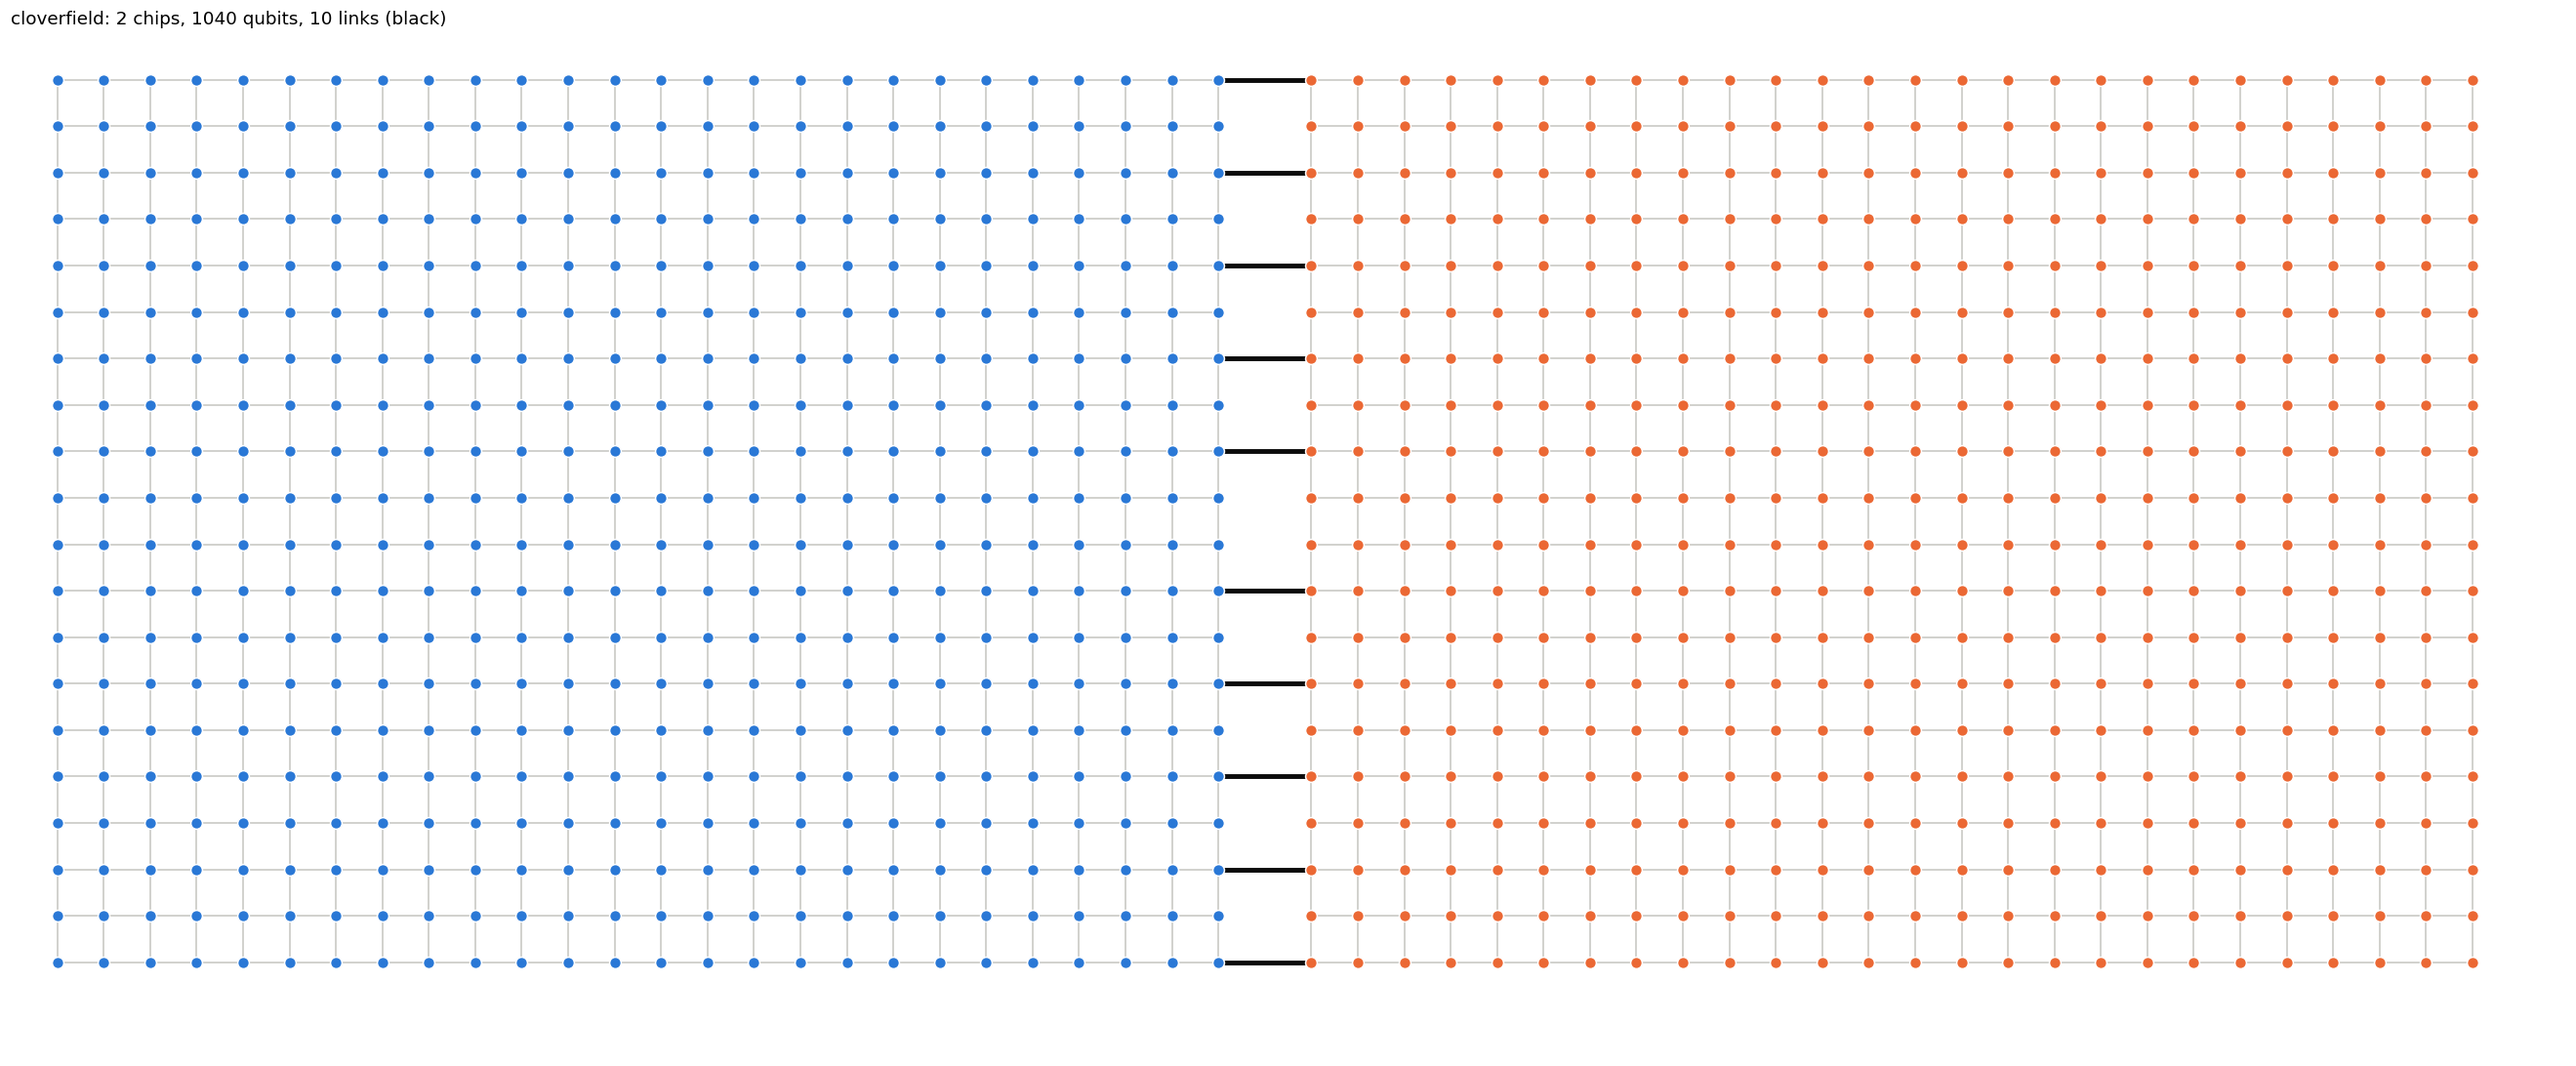


r3x2s: loom ghost, ghost max width 29
$ python3 nighthawk_qrack.py field plan --repo rcs-nighthawk --device r3x2s --loom ghost --ace-gpu --gpus 0 --chips-per-gpu 2 --vram-gb 22.03 --gtt 0 --ghost-max-width 29
cloverfield: 2 chips ['nighthawk120', 'nighthawk120'] on a 1 x 2 grid, 240 qubits
device r3x2s: r3x2 scaled to what runs here: the same two chips and ten l-couplers on 120-qubit chips; about 112 CZs per cycle, so the device's 10000 two-qubit gates are about 89 cycles of this field
colour   intra-chip CZ   link CZ
  A           120           0
  B            96          10
  C           120           0
  D           100           0
links: 10, loom ghost
  chip 0 site (0, 9) -- chip 1 site (0, 0)  colour B
  chip 0 site (1, 9) -- chip 1 site (1, 0)  colour B
  chip 0 site (2, 9) -- chip 1 site (2, 0)  colour B
  chip 0 site (4, 9) -- chip 1 site (4, 0)  colour B
  chip 0 site (5, 9) -- chip 1 site (5, 0)  colour B
  chip 0 site (6, 9) -- chip 1 site (6, 0)  colour B
  chip 0 site (

In [8]:
from IPython.display import Image, display

# 1. Plan the 1,040-qubit two-chip Nighthawk r3 system geometry and render its layout diagram
run_logged(["python3", "nighthawk_qrack.py", "field", "plan", "--repo", "rcs-nighthawk",
            "--device", "r3x2", "--backend", "exact", "--png", "r3x2.png"])
if Path("r3x2.png").is_file():
    display(Image("r3x2.png"))

# 2. The plans section 5 chose for r3x2s (240q), r3t (520q tiles) and clover6 (720q): the same arguments the
#    runs below use, so each verdict is about what will run on this host's detected RAM / VRAM
for dev_name, d in PATCH_CONFIG["devices"].items():
    print("\n" + "=" * 78)
    print(f"{dev_name}: loom {d['loom'] or 'none fits'}"
          + (f", ghost max width {d['ghost_max_width']}" if d["ghost_max_width"] else ""))
    print("=" * 78)
    run_logged(["python3", "nighthawk_qrack.py", "field", "plan", "--repo", "rcs-nighthawk",
                "--device", dev_name, *d["run_args"]])
    if not d["runnable"]:
        print(f"NOTE: {dev_name} does not fit this host with any loom "
              f"({'per-device VRAM' if PATCH_CONFIG['stack'] == 'opencl-gpu' else 'host RAM'} budget); "
              "it is skipped by the runs below")


In [9]:
import re

# 1. Quick 61-qubit Nighthawk r2 ACE Hamming simulation using the dimensioned --ace-max-width
ace_max_w = PATCH_CONFIG["ace_max_width"]
run_cmd = [
    "python3", "nighthawk_qrack.py", "run",
    "--repo", "rcs-nighthawk",
    "--backend", "ace",
    "--families", "hamming",
    "--sizes", "61",
    "--depths", "4",
    "--instances", "1",
    "--fold", "1",
    "--ace-max-width", str(ace_max_w),
    "--no-ace-error-detection",
    "--out", "colab_ace_61q.jsonl",
]
if PATCH_CONFIG["stack"] == "opencl-gpu":
    run_cmd += ["--ace-gpu", "--vram-gb", f"{PATCH_CONFIG['vram_gib']:g}"]
else:
    run_cmd += ["--cpu", "--max-rss-gb", f"{PATCH_CONFIG['max_rss_gb']:g}"]
r_ace = run_logged(run_cmd)

# 2. Quick 240-qubit two-chip Nighthawk r3 scaled (r3x2s) field simulation with the planned arguments
d = PATCH_CONFIG["devices"]["r3x2s"]
if d["runnable"]:
    print()
    r_field = run_logged([
        "python3", "nighthawk_qrack.py", "field", "run",
        "--repo", "rcs-nighthawk",
        "--device", "r3x2s",
        "--family", "hamming",
        "--protocol", "nnqab",
        "--fold", "1",
        "--depths", "4",
        "--instances", "1",
        "--no-ace-error-detection",
        "--out", "colab_r3x2s.jsonl",
        *d["run_args"],
    ])
else:
    r_field = None
    print("r3x2s does not fit this host: skipped")

# Summary of both quick runs
print("\n=== Quick runs ===")
# the run's closing table (also printed when the point was already in the .jsonl from an earlier run)
m = re.search(r"^61\s+4\s+1\s+\d+\s+([0-9.]+)", r_ace["out"], re.M)
print(f"  61q ACE, d4:          signal {m.group(1) if m else '?'}  ({r_ace['seconds']:.1f} s)"
      + (f"  FAILED: {failed_points(r_ace['out'])}" if failed_points(r_ace["out"]) else ""))
if r_field:
    m = re.search(r"^n\d+ hamming d4 .*?\bF ([0-9.]+)(.*)$", r_field["out"], re.M)
    extra = re.search(r"chips ([0-9. ]+?)\s+ghost drift ([0-9.]+)", m.group(2)) if m else None
    bad = failed_points(r_field["out"])
    print(f"  r3x2s field, d4:      signal {m.group(1) if m else '?'}"
          + (f", chips {extra.group(1).strip()}, ghost drift {extra.group(2)}" if extra else "")
          + f"  ({r_field['seconds']:.1f} s, loom {d['loom']})" + (f"  FAILED: {bad}" if bad else ""))


$ python3 nighthawk_qrack.py run --repo rcs-nighthawk --backend ace --families hamming --sizes 61 --depths 4 --instances 1 --fold 1 --ace-max-width 29 --no-ace-error-detection --out colab_ace_61q.jsonl --ace-gpu --vram-gb 22.03
Device #0, Building JIT.
# ace n=61 (64 sites), max width 29: lrc=4 lrr=2 torus=False, 31/102 couplers across simulators, 74 on a seam, 22 seam qubits, simulator widths [23, 23, 19, 15, 14, 14, 11], dense worst case 0.1 GB per worker
# note: --ace-gpu with wide patches: each V340 die has 8 GB; patches over ~29 qubits (fp32) will not fit on one
# cfg ace-57e6429e: backend ace, sizes [61], shots paper, twirls 64, lrc/lrr 4/4, max width 29 (layout per size above)
# 0 of 1 points already done
# progress n61 hamming K1 d4 p0 i0: circuit run 1/1, 100.0% of cycles, elapsed 0m00s, ETA 0m00s
n 61 hamming K1 d  4 part 0 inst 0  F 0.71817 +/- 0.0e+00  (0.39s)

== mirror Hamming-weight signal 1 - 2h of the ace backend (Dan Strano's observable; ideal 1; plain means over inst

### 5.1 Max-Memory Run (largest cloverfield that fits)

Runs the most memory-demanding cloverfield device whose plan fits the detected RAM / VRAM (section 5's table), and reports wall time, the Hamming signal per depth, and peak memory per GPU (`nvidia-smi` on NVIDIA, amdgpu sysfs on AMD) and on the host, next to what the planner predicted. Set `RUN_MAX_FIELD = False` to skip it; `MAX_RUN_DEPTHS` and `MAX_RUN_TIMEOUT_S` bound the run.


In [10]:
import re
import threading
import time

# Largest cloverfield run that the detected RAM / VRAM holds, measured: wall time, fidelity, peak memory
RUN_MAX_FIELD = True          # set False to skip
MAX_RUN_DEPTHS = ["4"]        # e.g. ["4", "8", "12"] for a decay curve (time grows with depth)
MAX_RUN_TIMEOUT_S = 3600      # the run is stopped after this many seconds
SAMPLE_EVERY_S = 1.0          # memory sampling interval

cands = [(n, d) for n, d in PATCH_CONFIG["devices"].items() if d["runnable"]]
gpu = PATCH_CONFIG["stack"] == "opencl-gpu"


def planned_gib(d):
    return d["plan_gib"] if gpu else (d["host_gib"] if d["host_gib"] is not None else d["plan_gib"])


if not RUN_MAX_FIELD:
    print("RUN_MAX_FIELD is False: skipped")
elif not cands:
    print("No cloverfield device fits this host's detected budget: nothing to run")
else:
    # the most demanding plan that fits, ghost loom before mean-field at equal memory
    name, d = max(cands, key=lambda nd: (planned_gib(nd[1]), nd[1]["loom"] == "ghost"))
    out_file = f"colab_max_{name}.jsonl"
    cmd = ["python3", "nighthawk_qrack.py", "field", "run",
           "--repo", "rcs-nighthawk", "--device", name,
           "--family", "hamming", "--protocol", "nnqab", "--fold", "1",
           "--depths", *MAX_RUN_DEPTHS, "--instances", "1",
           "--no-ace-error-detection", "--out", out_file, *d["run_args"]]
    print(f"Max-memory run: {name} ({d['n_chips']} chips, loom {d['loom']}"
          + (f", ghost max width {d['ghost_max_width']}" if d["ghost_max_width"] else "")
          + f", {d['links']} links), planned {planned_gib(d):.2f} GiB on "
          + (f"{len(PATCH_CONFIG['gpu_indices'])} GPU(s), {d['chips_per_gpu']} chip(s) per GPU" if gpu else "the CPU"))

    # memory sampler: per-GPU used memory (nvidia-smi / amdgpu sysfs) and host RAM in use
    base = device_mem_used_gib(OCL_DEVS)
    peak = dict(base)
    stop = threading.Event()

    def sample():
        while not stop.is_set():
            for k, v in device_mem_used_gib(OCL_DEVS).items():
                peak[k] = max(peak.get(k, v), v)
            stop.wait(SAMPLE_EVERY_S)

    th = threading.Thread(target=sample, daemon=True)
    th.start()
    try:
        r = run_logged(cmd, timeout=MAX_RUN_TIMEOUT_S)
    finally:
        stop.set()
        th.join()

    print(f"\n=== Max-memory run: {name} ===")
    print(f"  wall time            {r['seconds']:.1f} s" + ("  (TIMED OUT)" if r["timed_out"] else ""))
    if failed_points(r["out"]):
        print(f"  FAILED               {failed_points(r['out'])}")
    for m in re.finditer(r"^n(\d+) hamming d\s*(\d+).*?\bF ([0-9.]+)(.*)$", r["out"], re.M):
        extra = re.search(r"chips ([0-9. ]+?)\s+ghost drift ([0-9.]+)", m.group(4))
        print(f"  d{m.group(2):<3s} signal {m.group(3)}"
              + (f"  chips {extra.group(1).strip()}  ghost drift {extra.group(2)}" if extra else ""))
    print(f"  {'memory':20s} {'before':>8s} {'peak':>8s} {'run used':>9s}  (GiB)")
    labels = {d_["index"]: f"GPU {d_['index']} {d_['device'][:12]}" for d_ in OCL_DEVS}
    for k in sorted(peak, key=lambda k: (k == "host", str(k))):
        print(f"  {('host RAM' if k == 'host' else labels.get(k, str(k))):20s} {base.get(k, 0):8.2f} "
              f"{peak[k]:8.2f} {peak[k] - base.get(k, 0):9.2f}")
    if gpu and not any(k != "host" for k in peak):
        print("  (no per-GPU memory counter readable here: neither nvidia-smi nor amdgpu sysfs)")
    print(f"  planned              {planned_gib(d):.2f} GiB (sum of the chips' peaks, nighthawk_qrack.py field plan)")
    print(f"  records              {out_file}")


Max-memory run: r3t (4 chips, loom ghost, ghost max width 27, 27 links), planned 19.10 GiB on 1 GPU(s), 4 chip(s) per GPU
$ python3 nighthawk_qrack.py field run --repo rcs-nighthawk --device r3t --family hamming --protocol nnqab --fold 1 --depths 4 --instances 1 --no-ace-error-detection --out colab_max_r3t.jsonl --loom ghost --ace-gpu --gpus 0 --chips-per-gpu 4 --vram-gb 22.03 --gtt 0 --ghost-max-width 27
# --protocol nnqab: single-qubit ensemble set to nnqab (as nn_qab.py)
# cloverfield field-99cff25d: 4 chips ['nighthawk120t', 'nighthawk140', 'nighthawk120t', 'nighthawk140'] (2x2), 520 qubits, 27 links (19 facing pairs skipped: no common free colour, or no ghost room under the caps), loom ghost, backend ace, theta nnqab, family hamming, protocol nnqab
# looms: 1 on GPUs 0, 0 on the CPU; 1 points
Device #0, Building JIT.
Device #0, Building JIT.
Device #0, Building JIT.
Device #0, Building JIT.
# loom g0: chips nighthawk120t pid 28655 on 0 (17 ghosts, patch widths [20, 26, 27, 27, 23,

## 6. Execute `nighthawk_graph.py` on Measured Results

Generate summary tables, multi-chip Cloverfield topology posters (`r3_topo.jsonl`), and RCS / Mirror / FXEB / Hamming figures (`../nighthawk/rcs-nighthawk/nighthawk.tar.gz`) using [`nighthawk_graph.py`](https://github.com/twobombs/thereminq-examples/blob/main/devices/nighthawk-r3/nighthawk_graph.py).

### 6.1 Cloverfield (`clover6`, 720 Qubits) Measured Topologies (`r3_topo.jsonl`)

Plot the measured 720-qubit Cloverfield records across `ring`, `hub 1`, and `grid + 0-5,2-3` topologies (view 29, Hamming views 12–13, and one-page topology posters).

field-093ed631: 4 points, field-25da32df: 4 points, field-52dcd722: 4 points, field-650ca988: 4 points, field-6edd8b39: 4 points, field-9128f452: 4 points; hwxeb circuits: 0; shor9 records: 0; ghz records: 0; shor_bridge records: 0; dual_r1 rows: 0; dual_map chains: 0; shor_alg circuits: 0; read 10:45:22
wrote 24 points of 6 configurations to plots_r3/r3_topo.csv
field-093ed631: 4 points, field-25da32df: 4 points, field-52dcd722: 4 points, field-650ca988: 4 points, field-6edd8b39: 4 points, field-9128f452: 4 points; hwxeb circuits: 0; shor9 records: 0; ghz records: 0; shor_bridge records: 0; dual_r1 rows: 0; dual_map chains: 0; shor_alg circuits: 0; read 10:45:23
saved plots_r3/12_hm.png
/content/thereminq-examples/devices/nighthawk-r3/nighthawk_graph.py:1205: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  a1.legend(fontsize=8, ncol=2)
/content/thereminq-examples

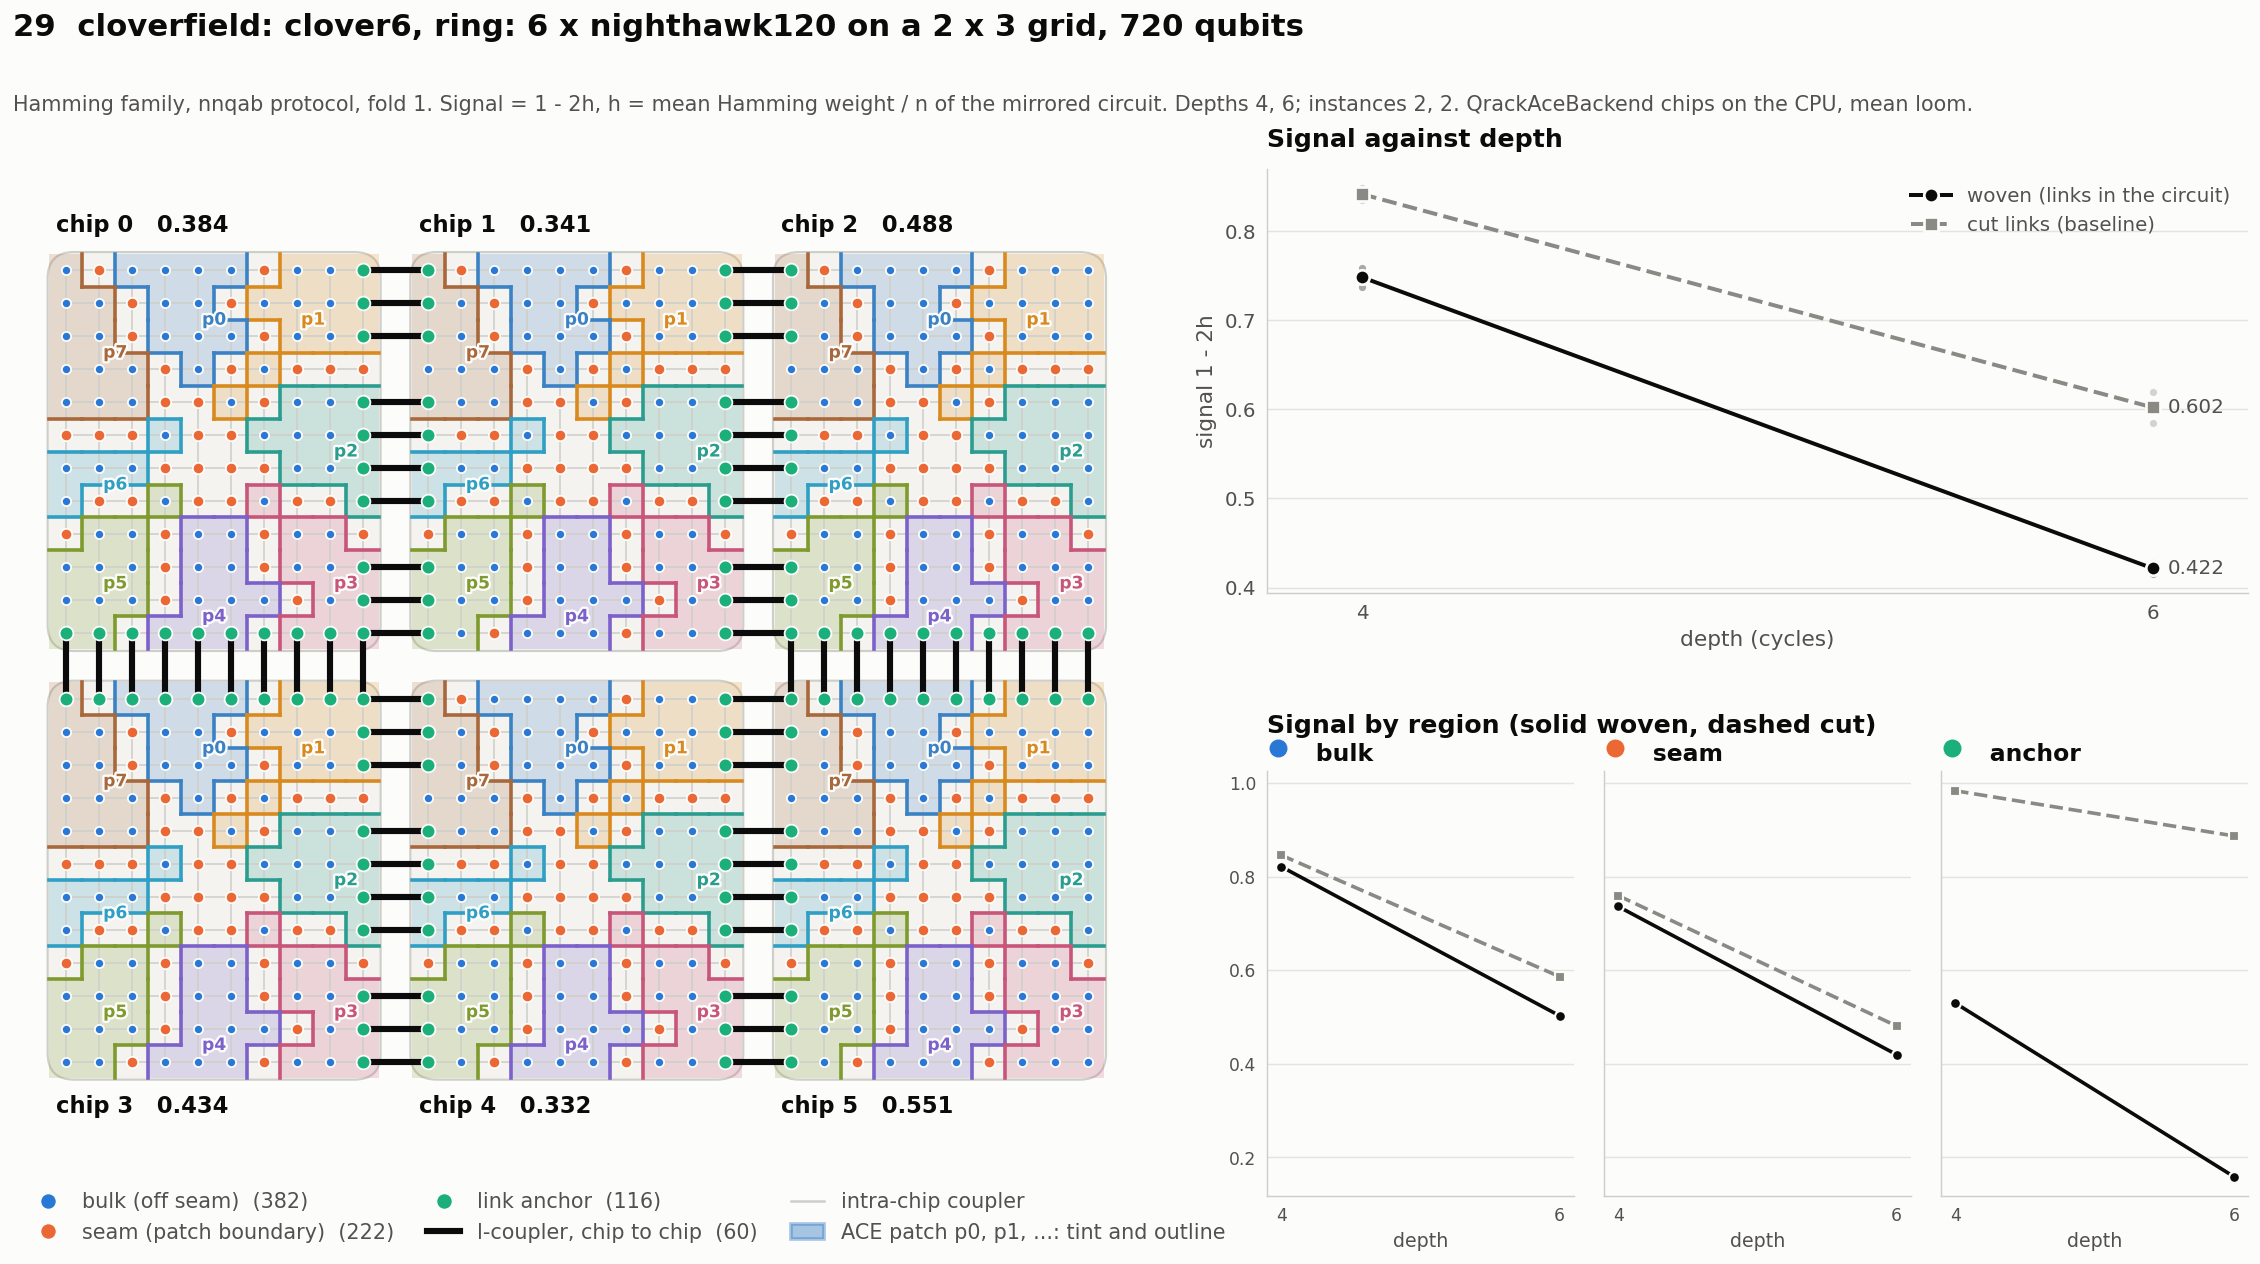

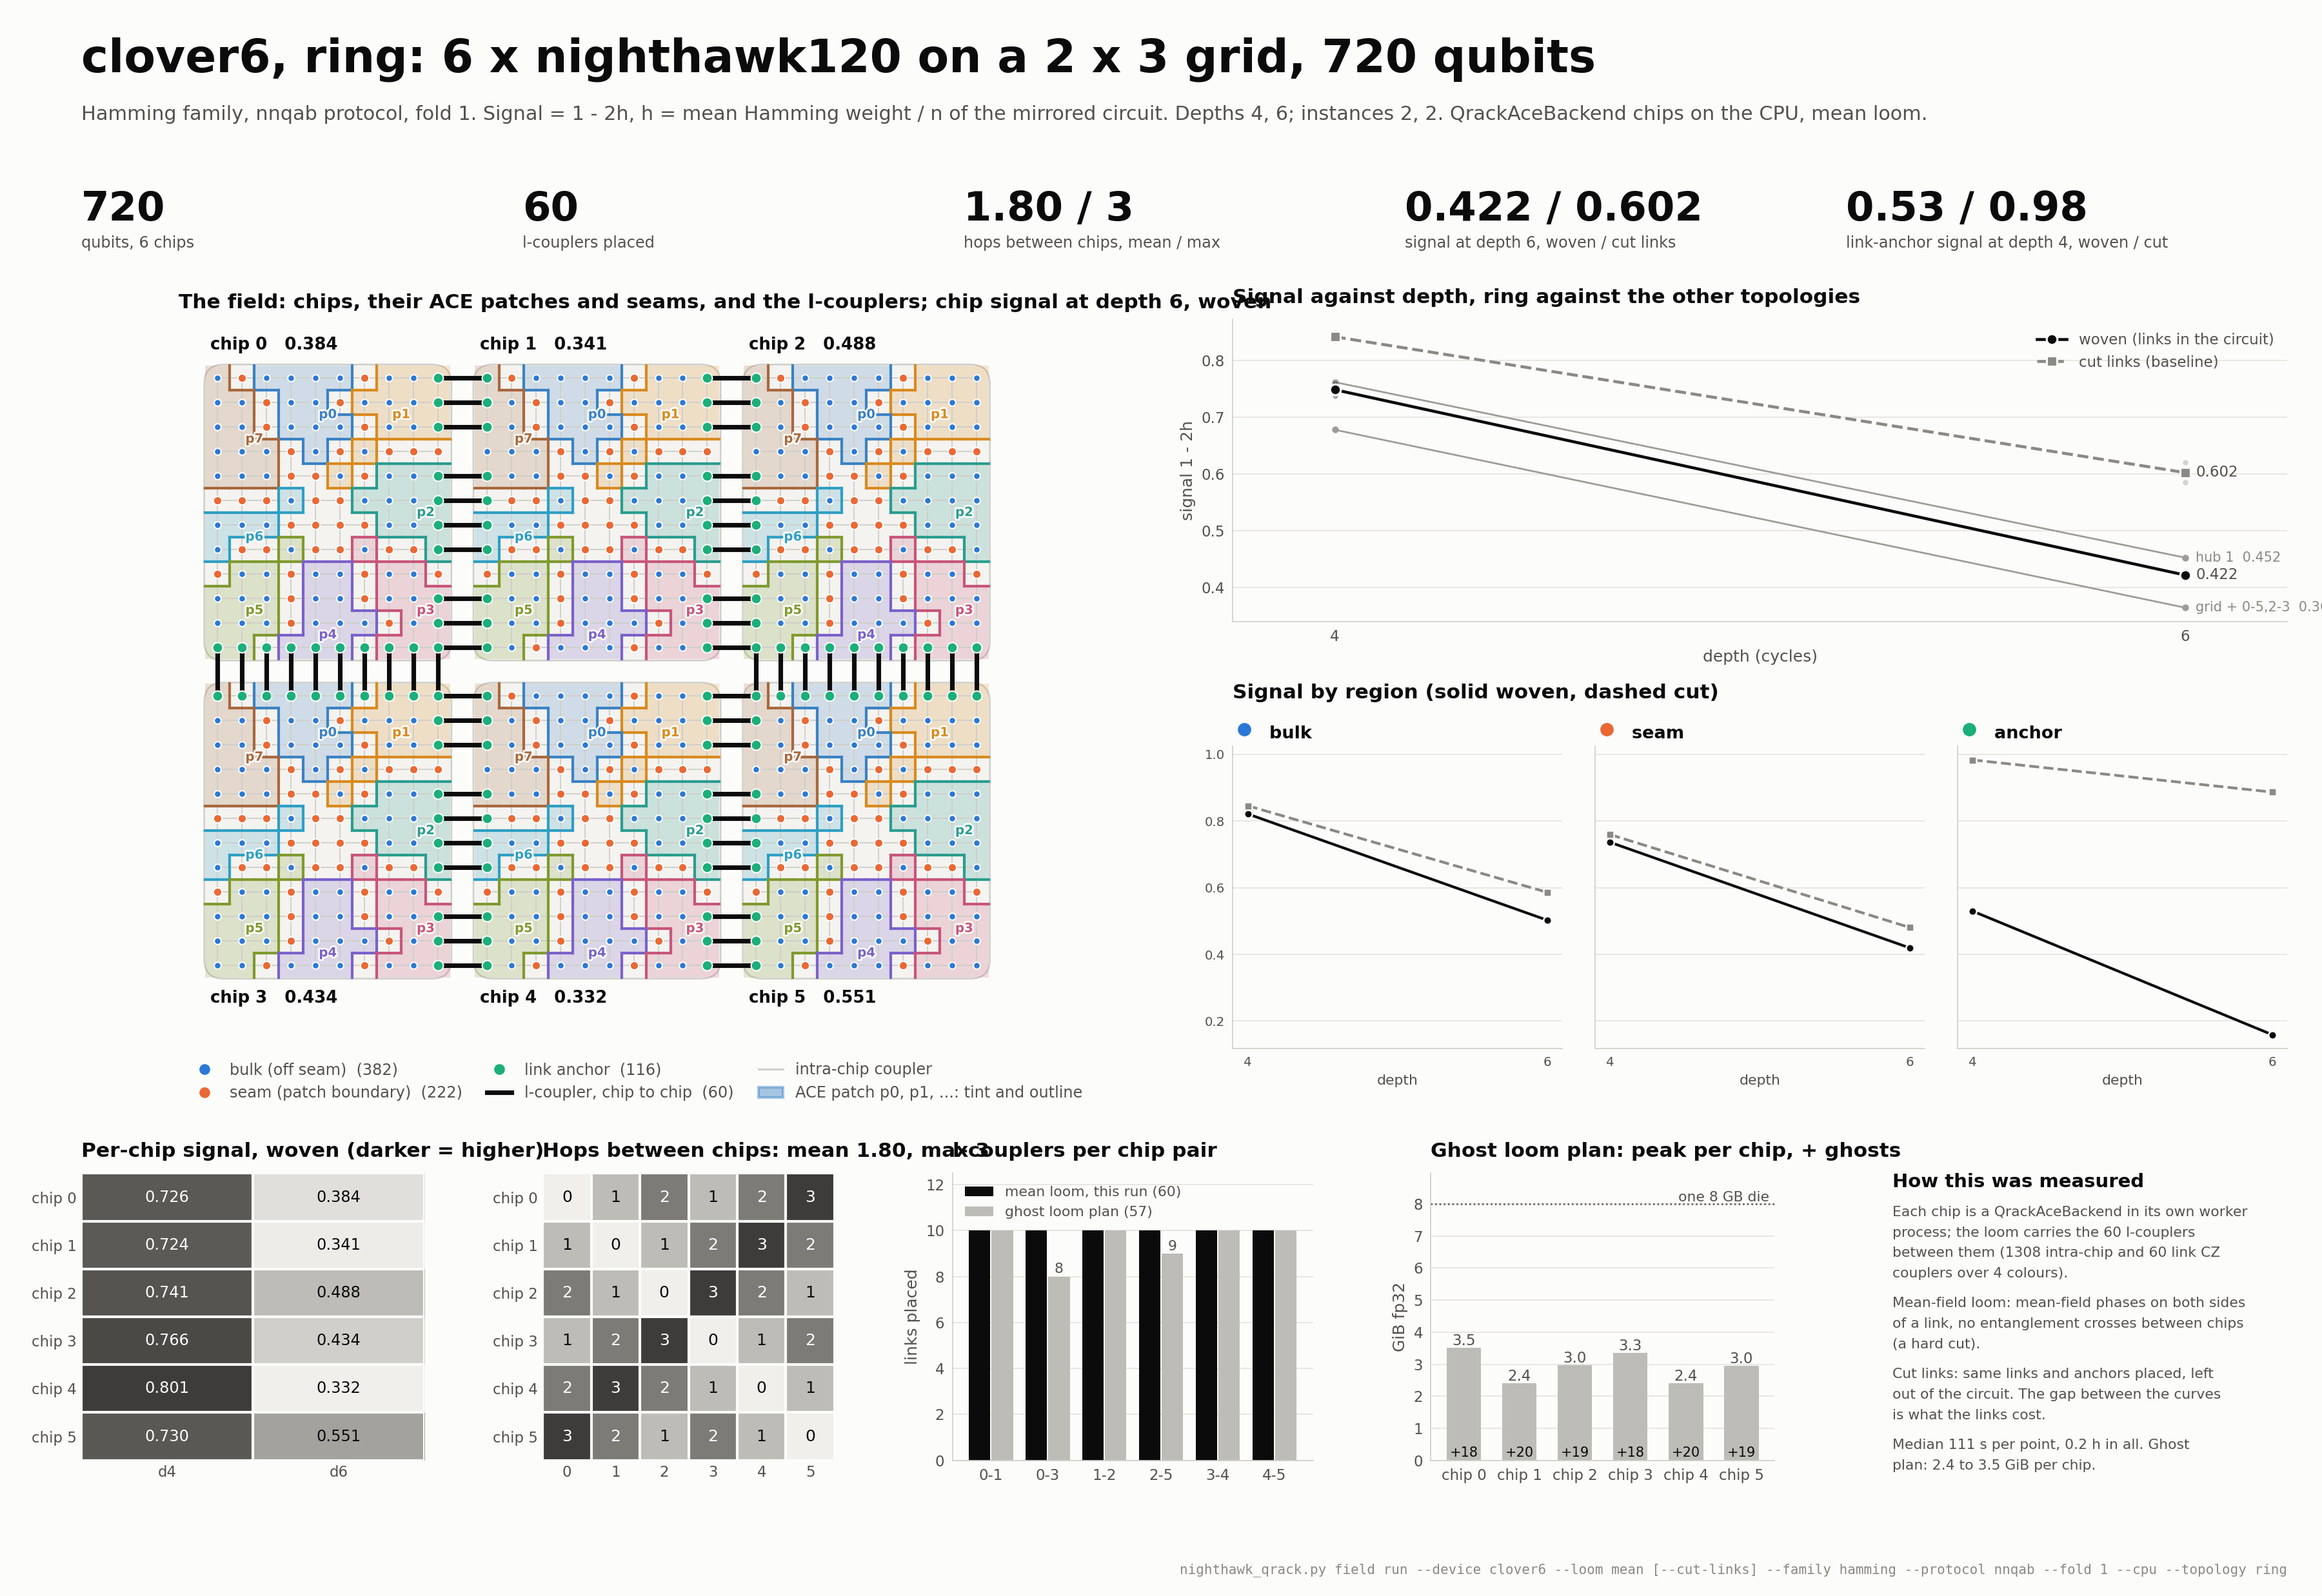

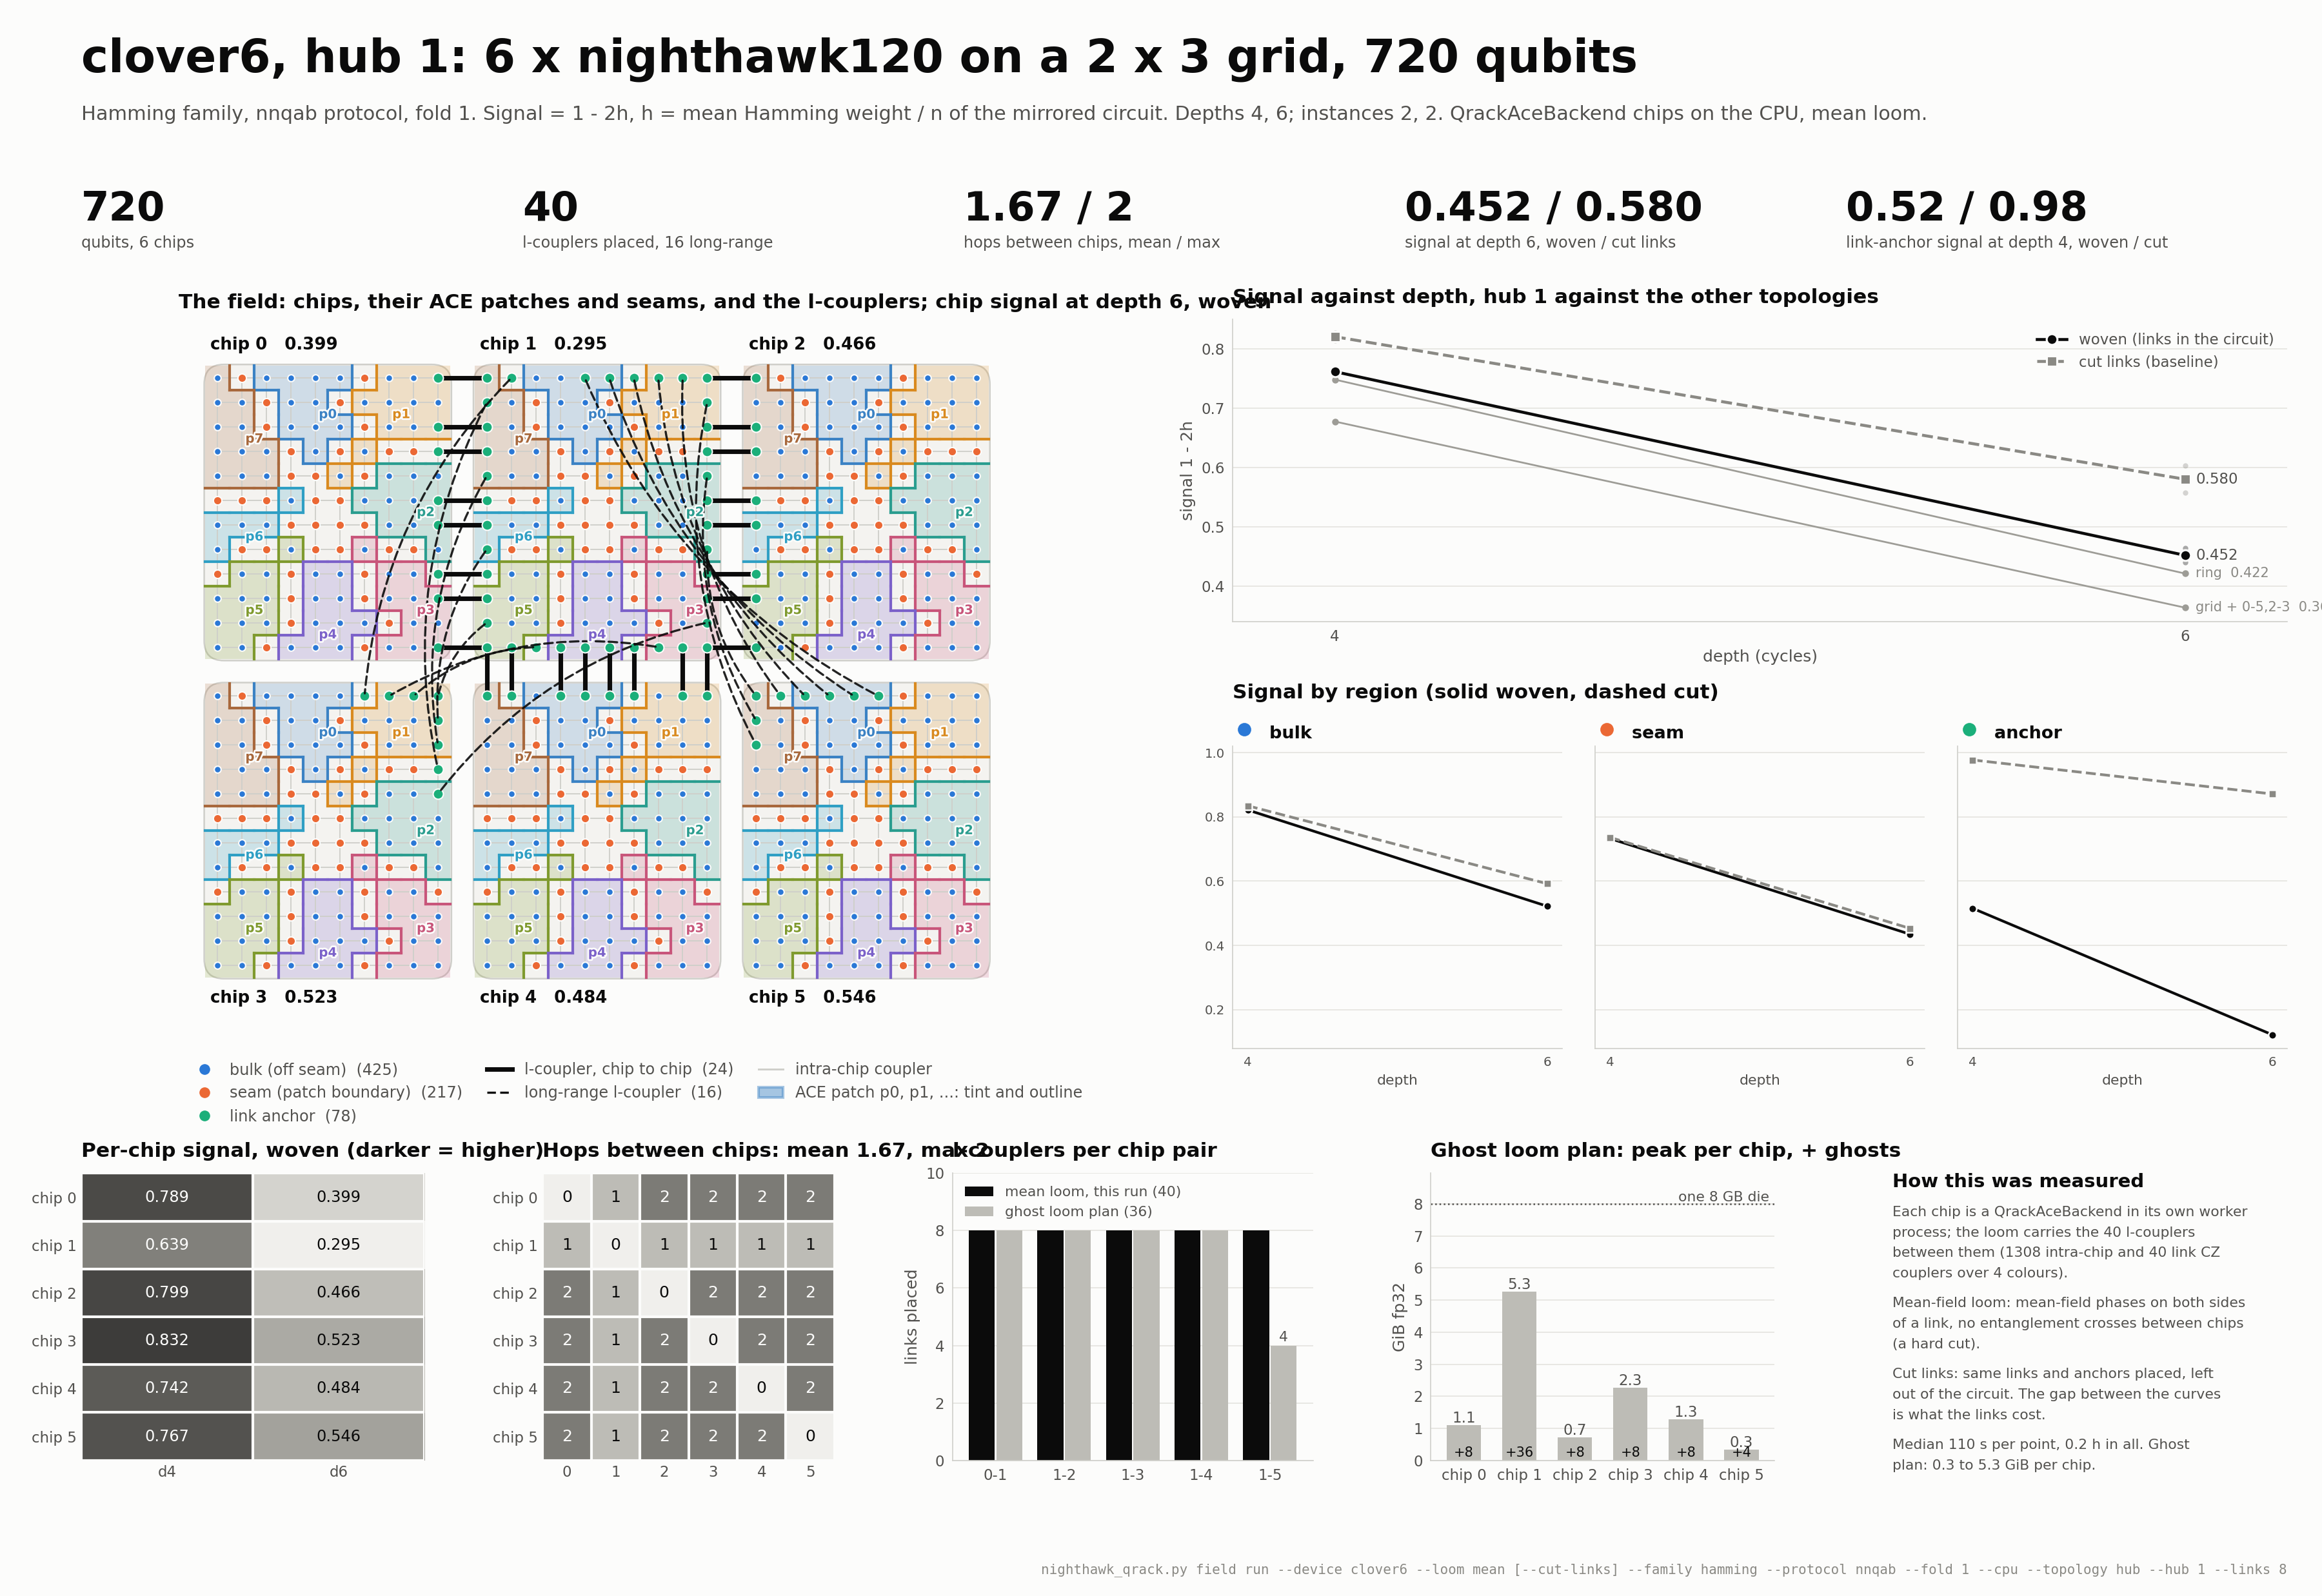

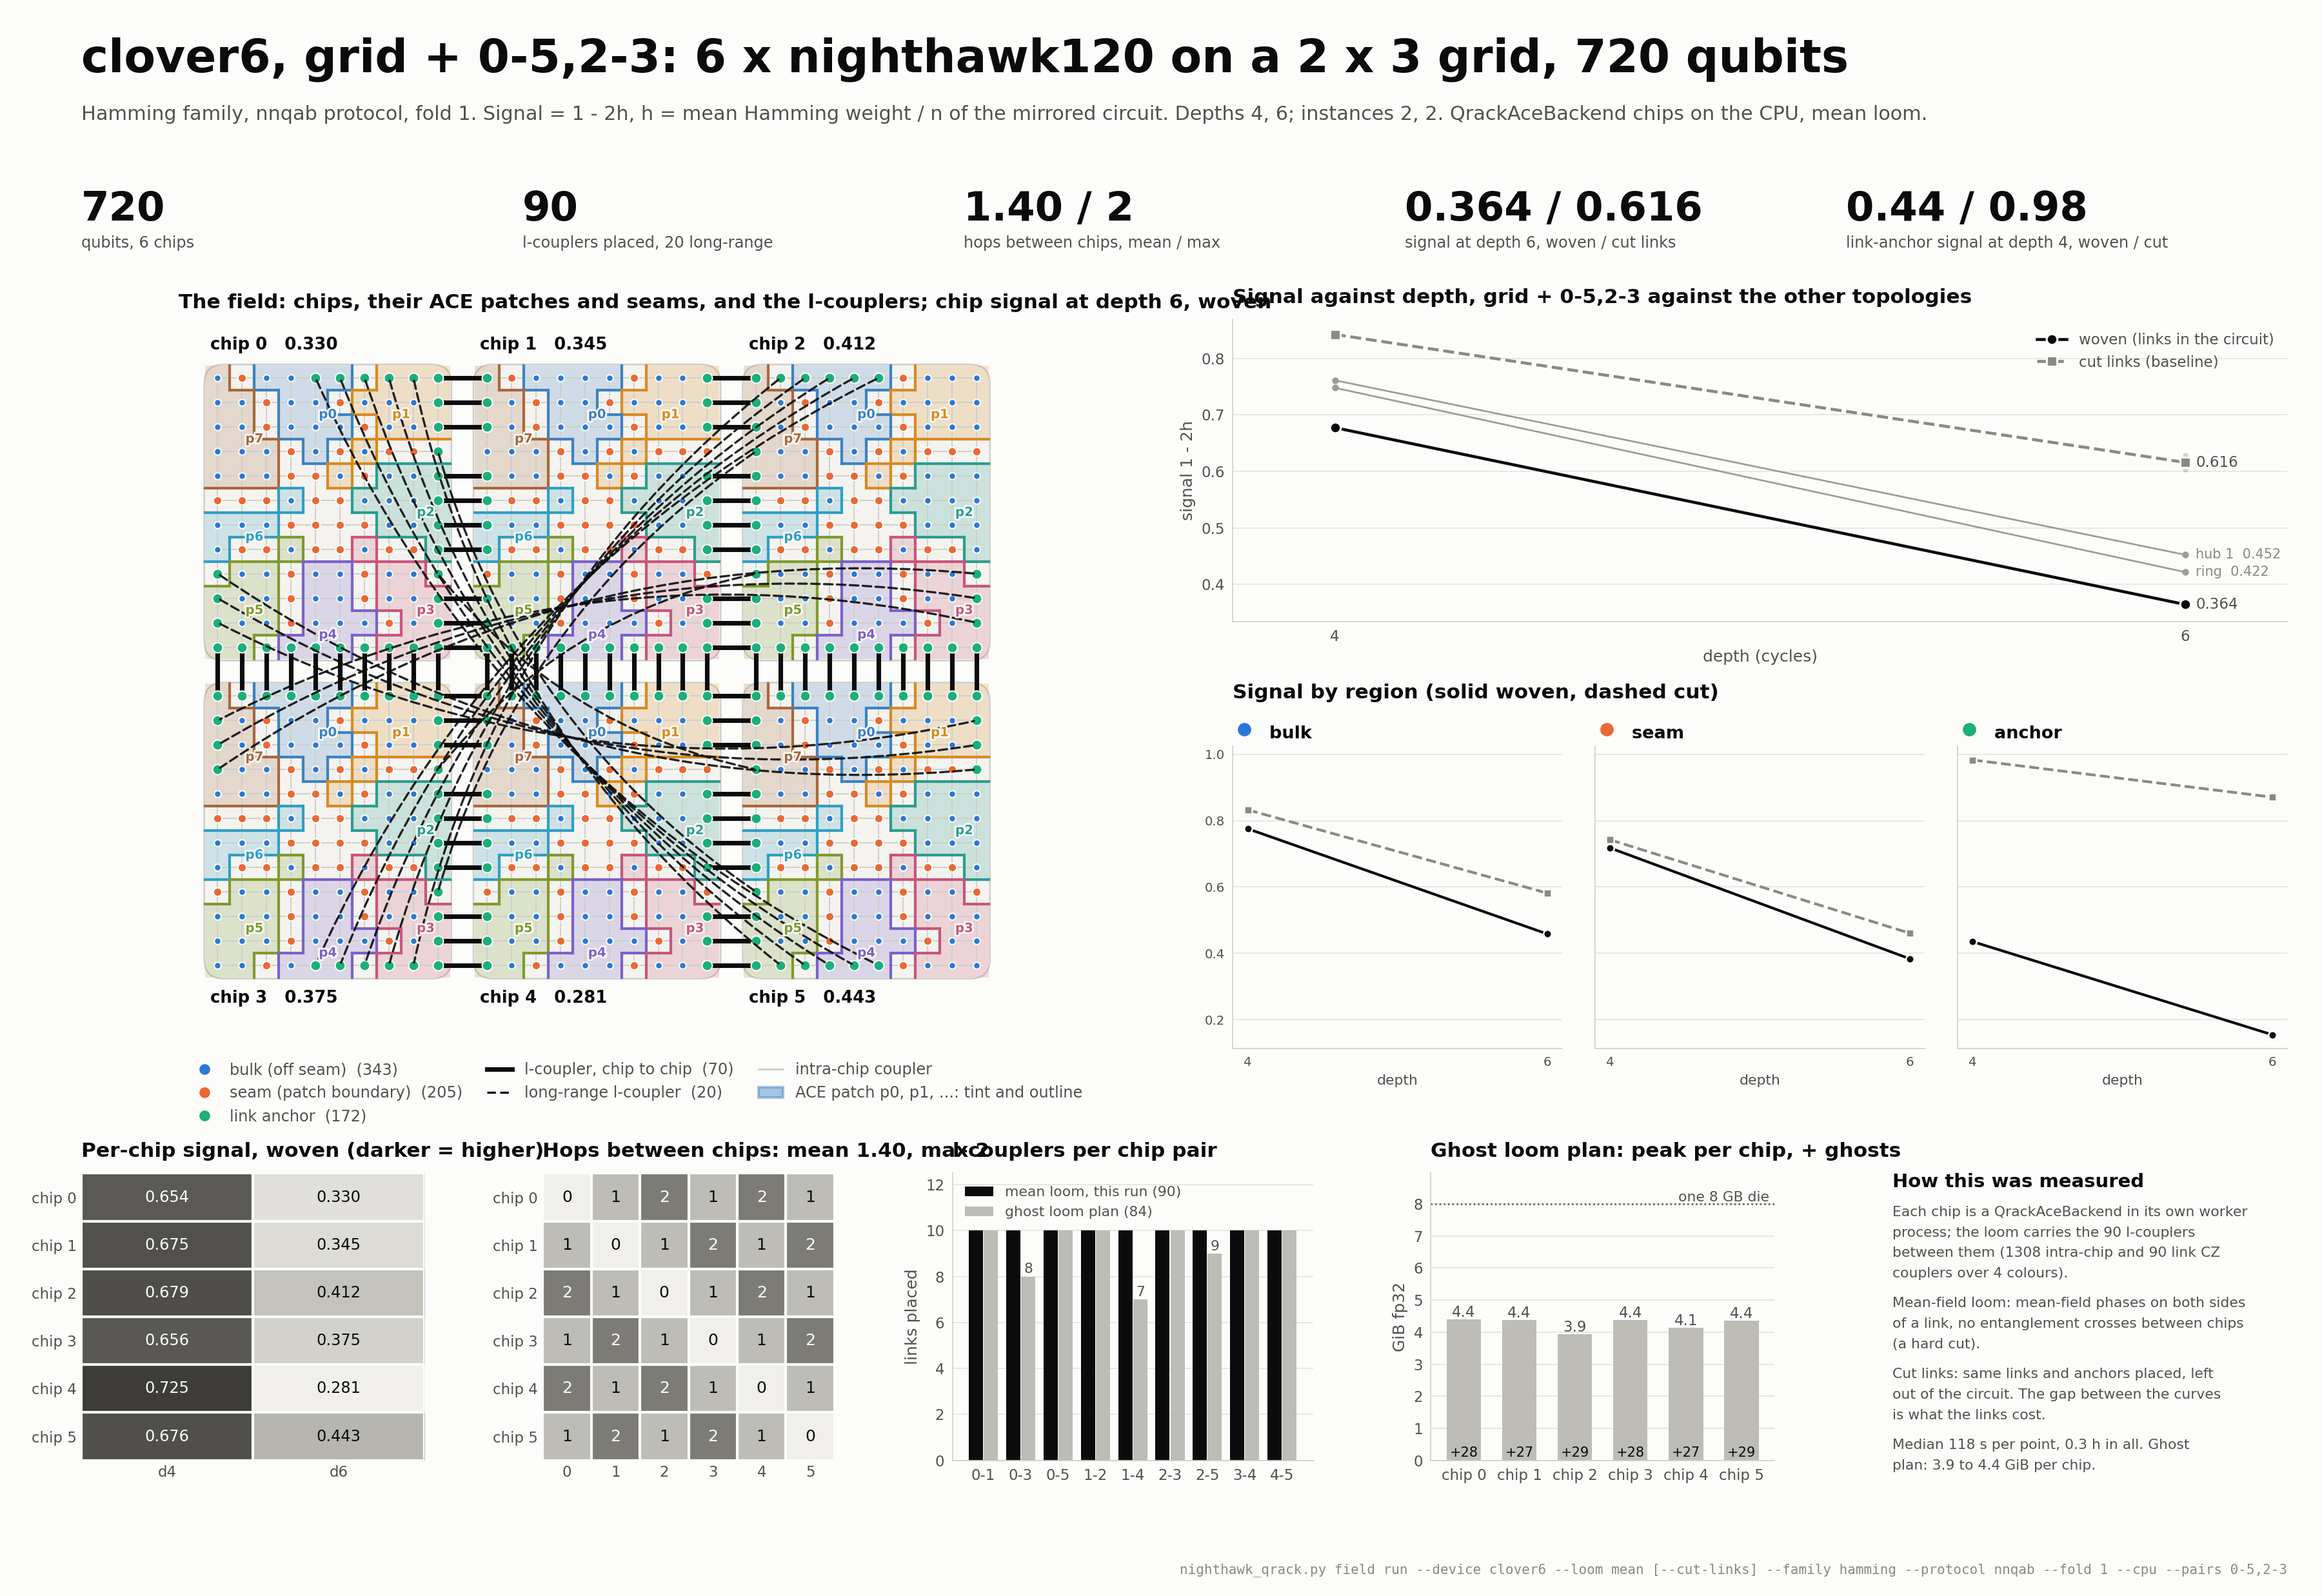

In [11]:
from pathlib import Path
from IPython.display import Image, display

Path("plots_r3").mkdir(exist_ok=True)

!python3 nighthawk_graph.py --out r3_topo.jsonl --table plots_r3/r3_topo.csv
!python3 nighthawk_graph.py --out r3_topo.jsonl --save plots_r3 --figs 12,13,29
!python3 nighthawk_graph.py --out r3_topo.jsonl --poster plots_r3/r3_topo_ring.png --poster-topology ring
!python3 nighthawk_graph.py --out r3_topo.jsonl --poster plots_r3/r3_topo_hub1.png --poster-topology "hub 1"
!python3 nighthawk_graph.py --out r3_topo.jsonl --poster plots_r3/r3_topo_grid_shortcuts.png --poster-topology "grid + 0-5,2-3"

for img_name in [
    "29_fld.png",
    "r3_topo_ring.png",
    "r3_topo_hub1.png",
    "r3_topo_grid_shortcuts.png",
]:
    p = Path("plots_r3") / img_name
    if p.is_file():
        display(Image(filename=str(p)))

### 6.2 Measured RCS, Mirror, Forward XEB, and Hamming Sweeps (`nighthawk.tar.gz`)

Extract the measured sweep archive (`../nighthawk/rcs-nighthawk/nighthawk.tar.gz`, 36 record files / 949 points across 24 configurations) and run `nighthawk_graph.py` to generate the comparison table and views 1–13.

$ python3 /content/thereminq-examples/devices/nighthawk-r3/nighthawk_graph.py --table /content/thereminq-examples/devices/nighthawk-r3/plots_measured/harvest.csv
Device #0, Building JIT.
harvesting 36 record files: big_ace.jsonl, big_tile.jsonl, big_var.jsonl, clean_ace.jsonl, clean_ace_c4r7.jsonl, clean_ace_c7r4.jsonl, clean_ace_seam5.jsonl, clean_ace_seam6.jsonl, clean_ace_seam7.jsonl, clvk_t1.jsonl, dan_hamming_36.jsonl, dan_hamming_40.jsonl, dan_hamming_45.jsonl, dan_hamming_49.jsonl, dan_hamming_53.jsonl, dan_hamming_57.jsonl, dan_hamming_61.jsonl, lay_1_7.jsonl, lay_2_2.jsonl, lay_2_7.jsonl, lay_4_3.jsonl, lay_4_4.jsonl, mirror61_dan_d16.jsonl, mirror61_dan_nnqab_cpu.jsonl, mirror61_dan_prob_clvk.jsonl, mirror61_dan_prob_cpu.jsonl, mirror61_dan_prob_pocl.jsonl, mirror61r2_haar.jsonl, pocl_d8_cap.jsonl, pocl_d8_debug.jsonl, repro_d12_cpu.jsonl, tile_1_7.jsonl, tile_2_2.jsonl, tile_2_7.jsonl, tile_4_3.jsonl, tile_4_4.jsonl
ace-01b20966: 149 points, ace-065b88fb: 7 points, ace-0787b

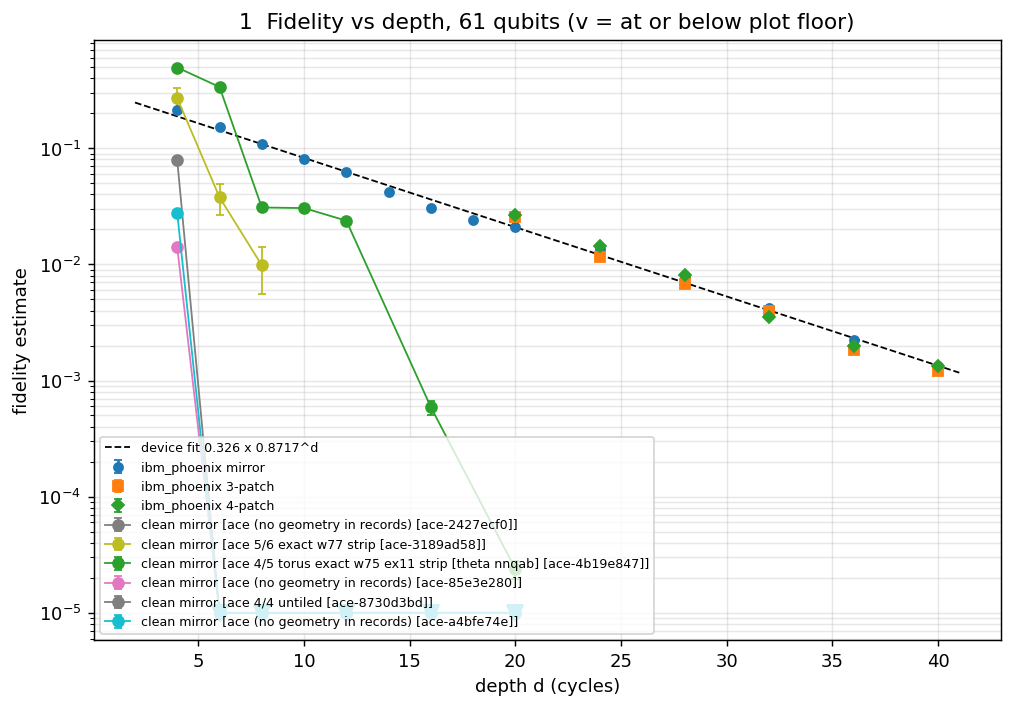


=== 2_sweep.png ===


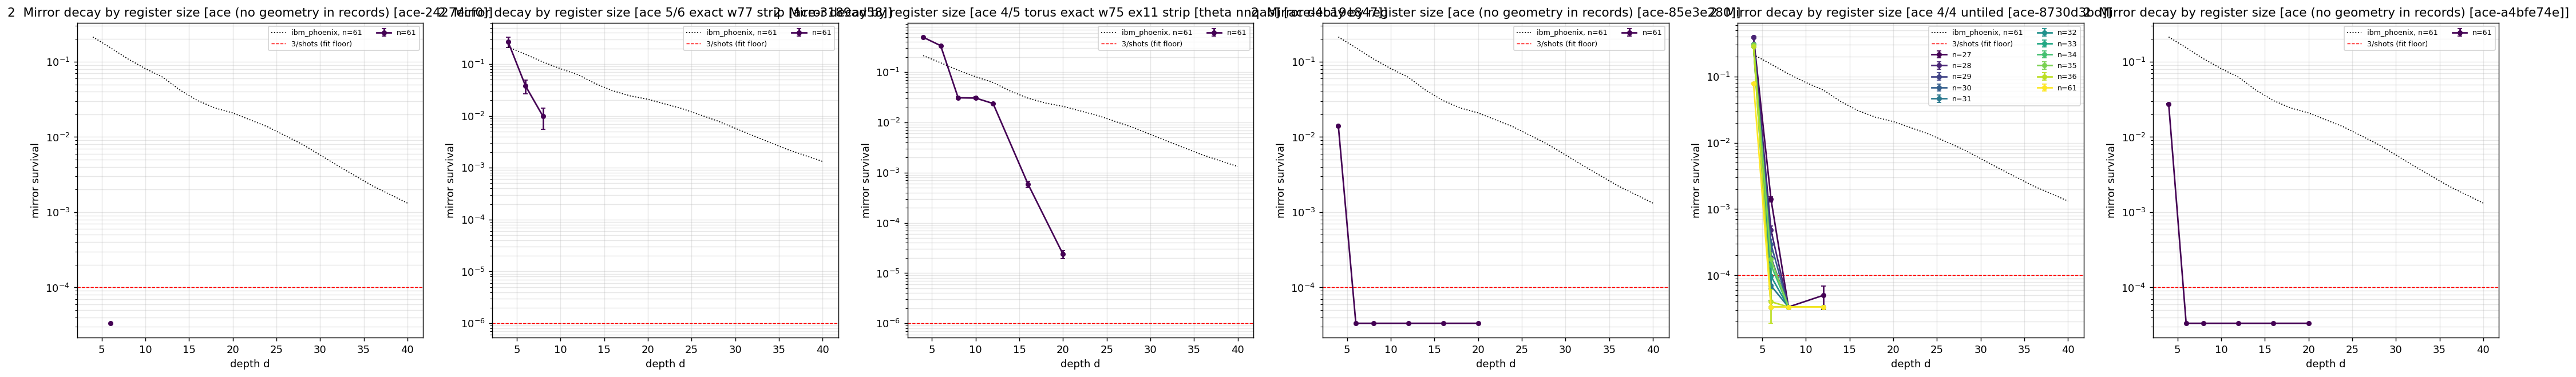


=== 3_bN.png ===


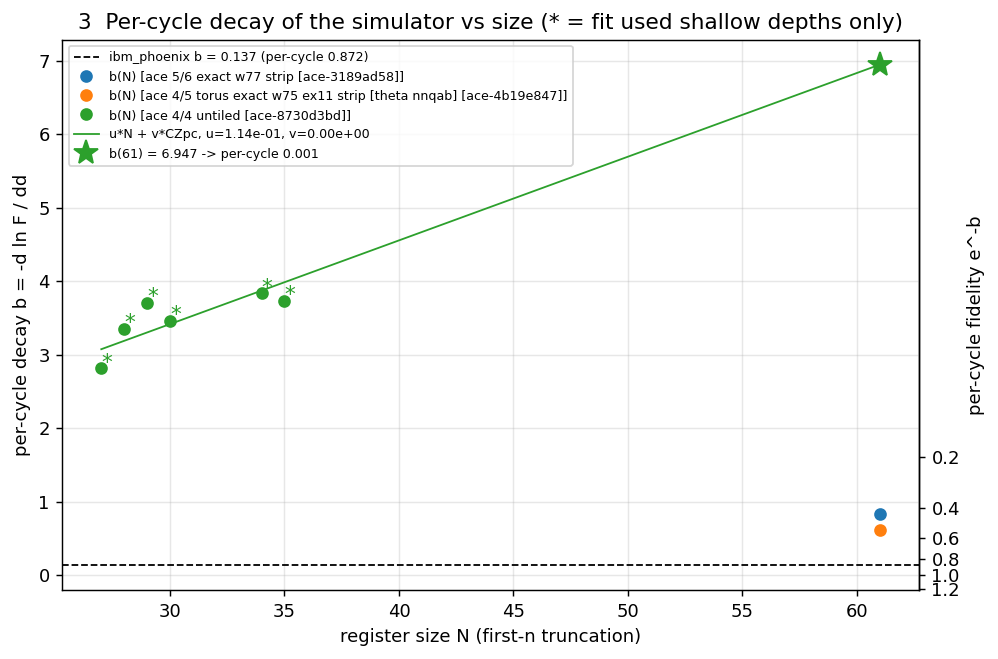


=== 4_mbits_ace-2427ecf0.png ===


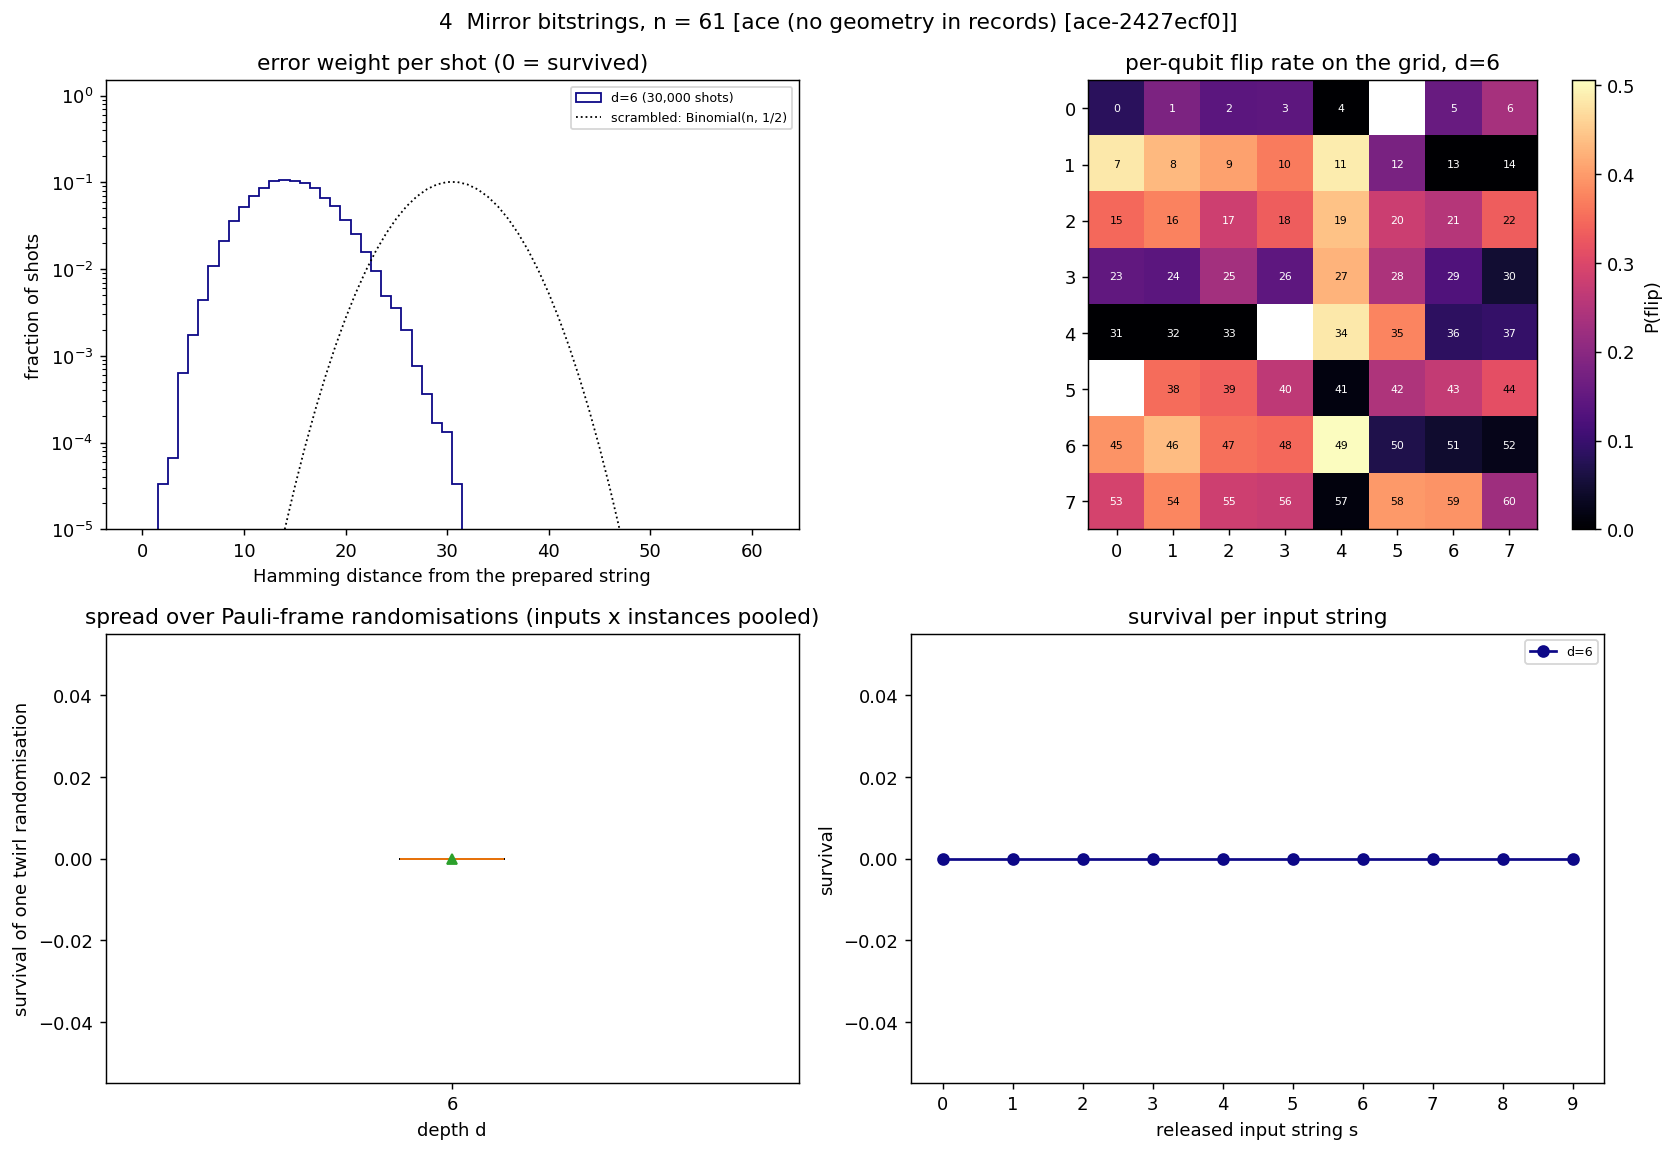


=== 4_mbits_ace-a4bfe74e.png ===


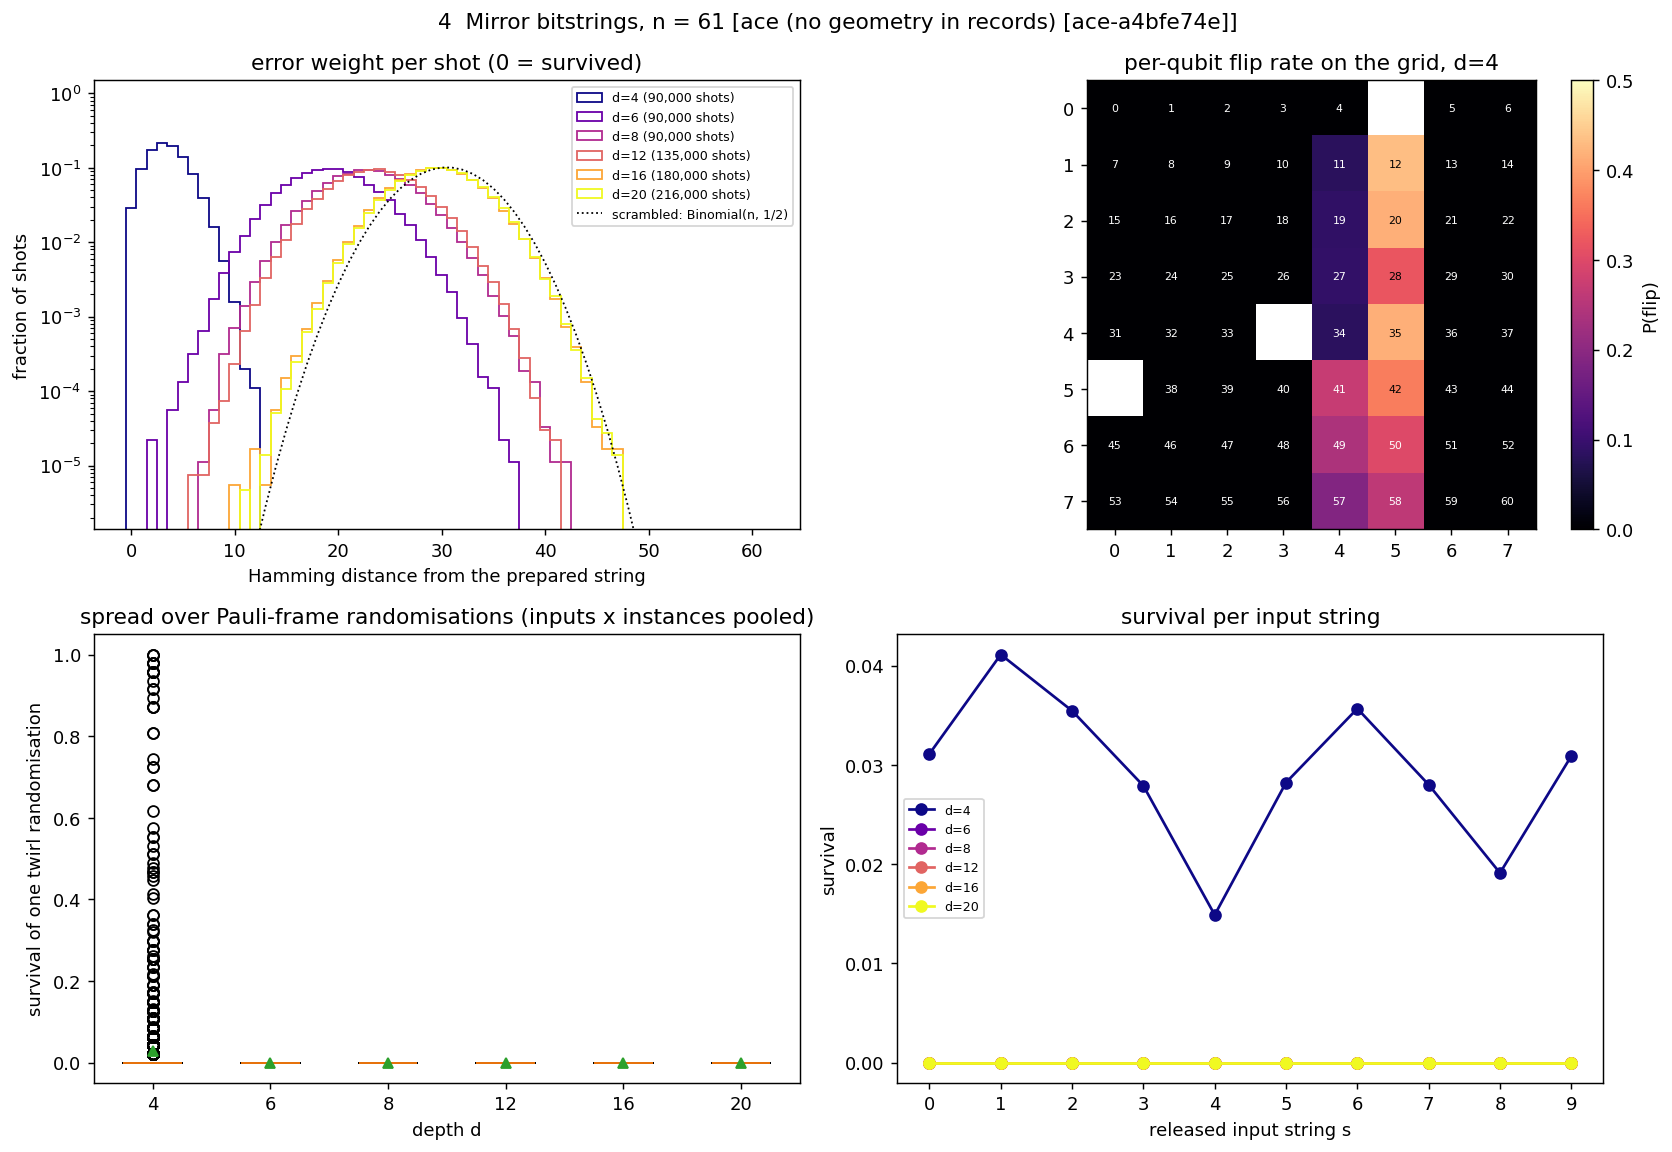


=== 4_mbits_ace-85e3e280.png ===


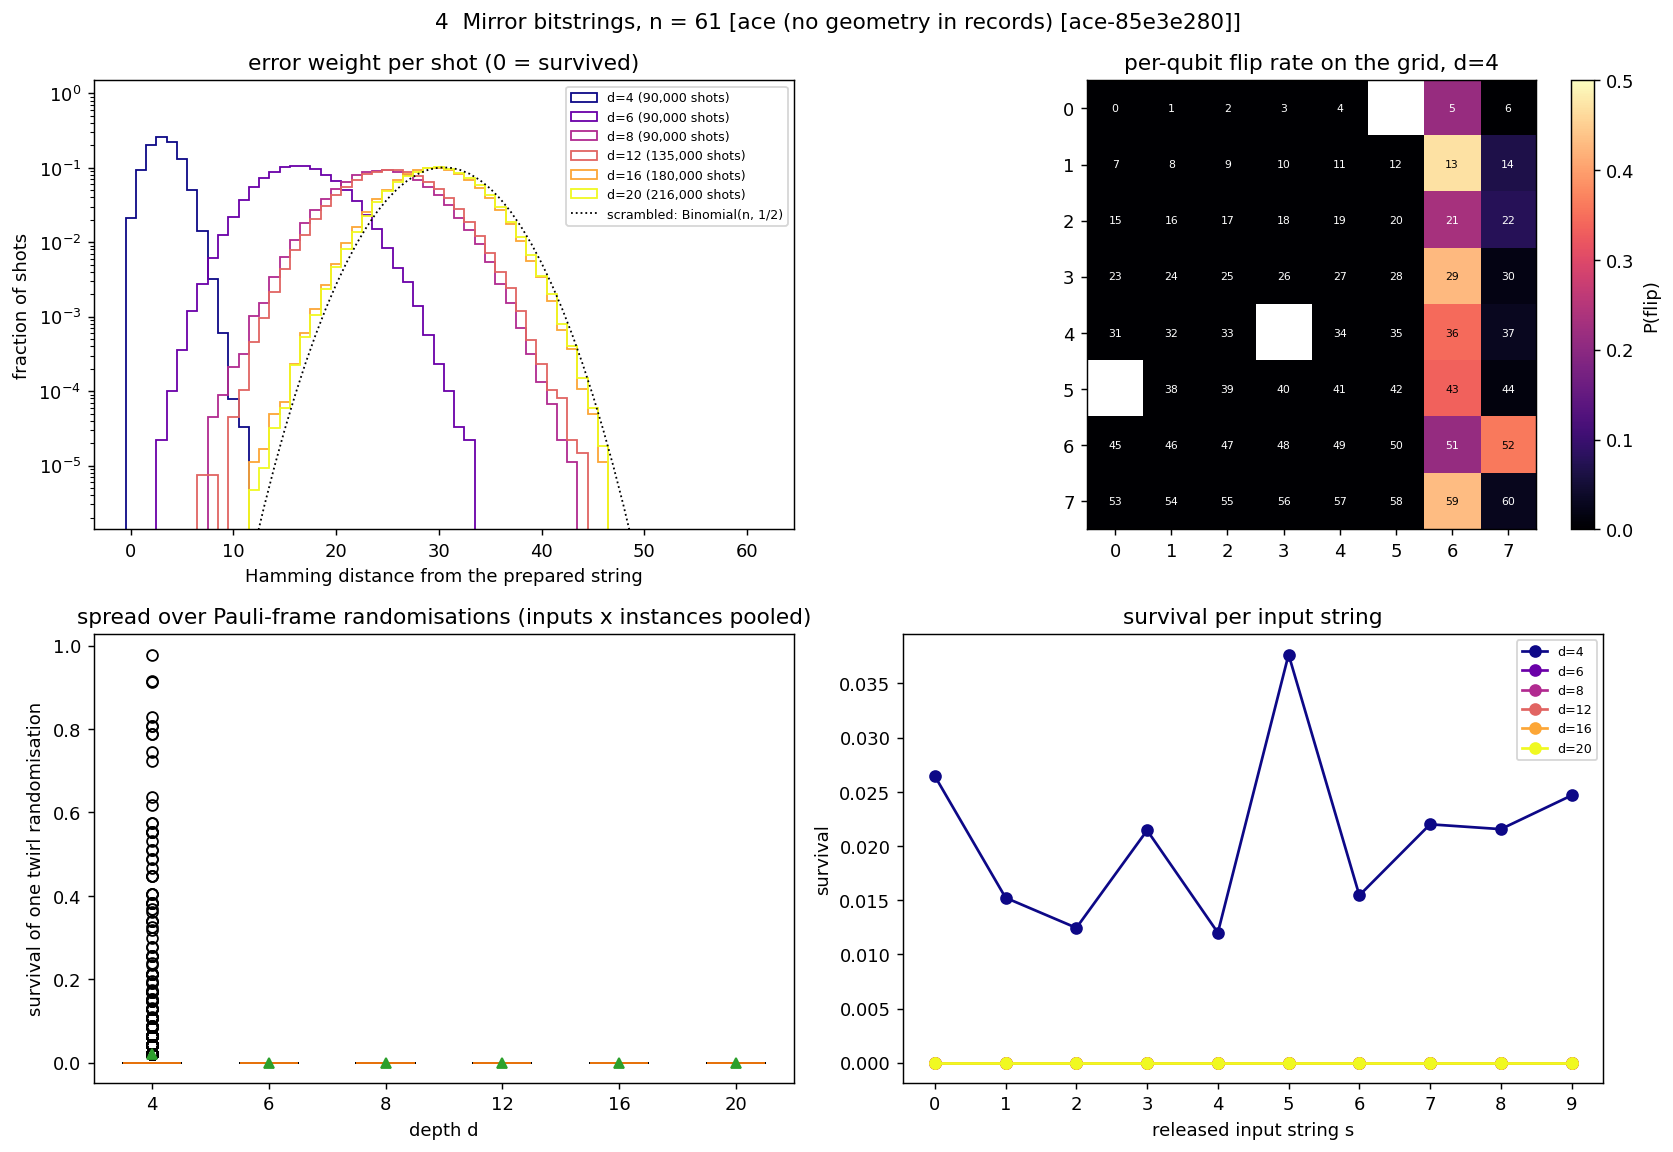


=== 6_release.png ===


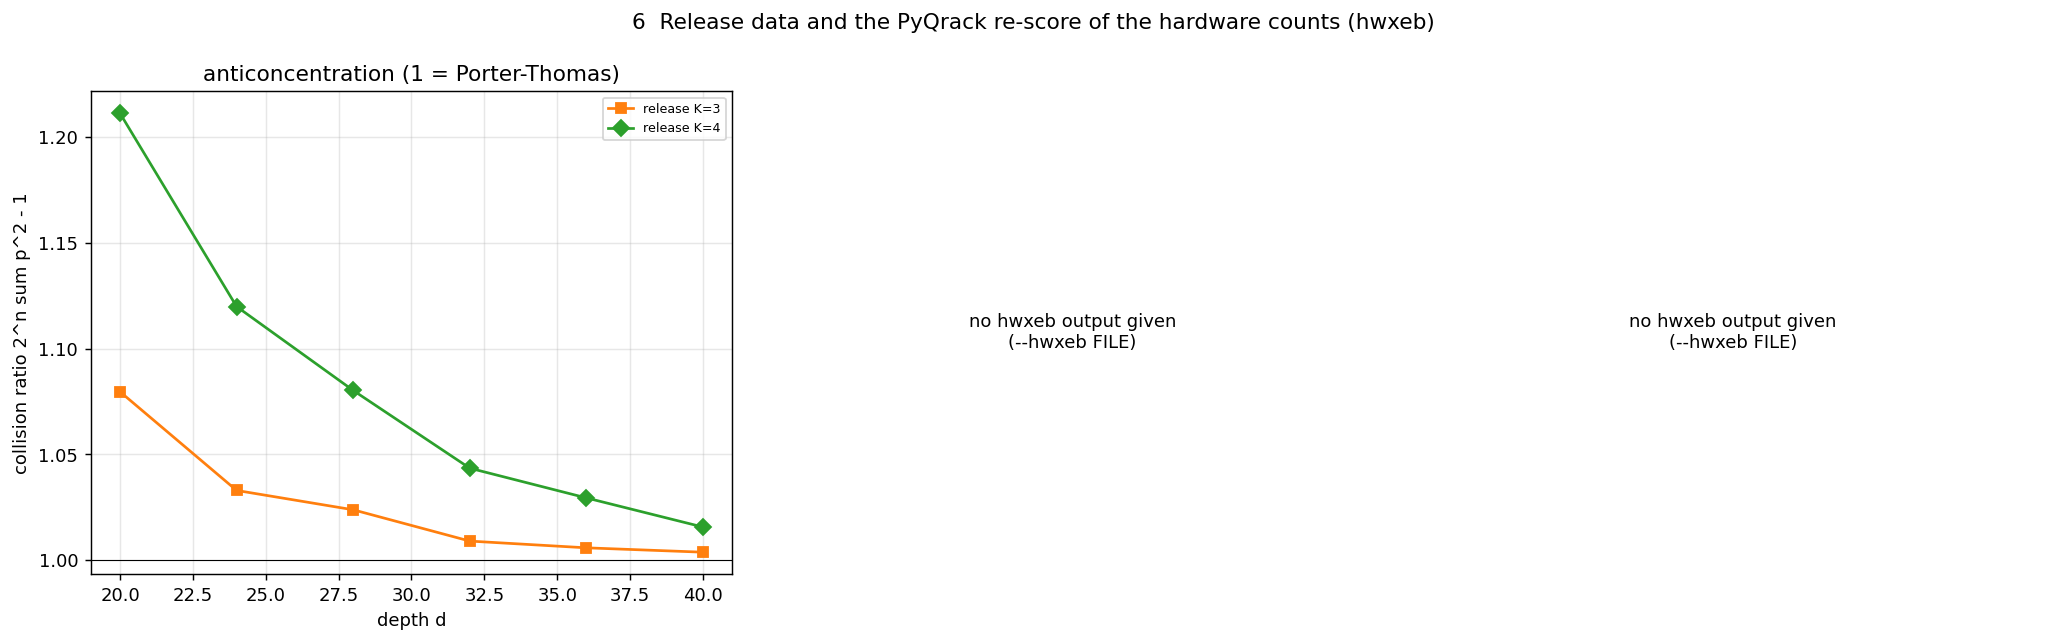


=== 7_cost.png ===


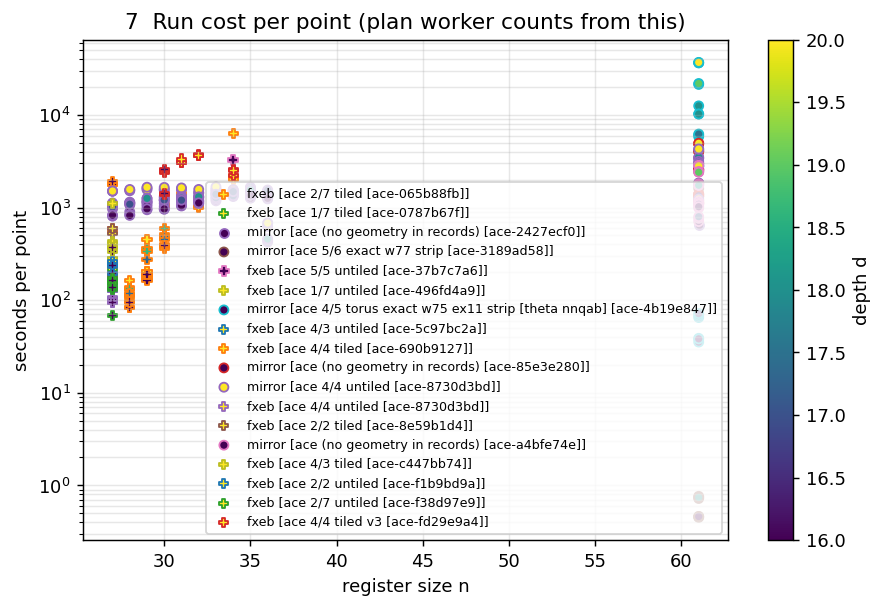


=== 8_fxd.png ===


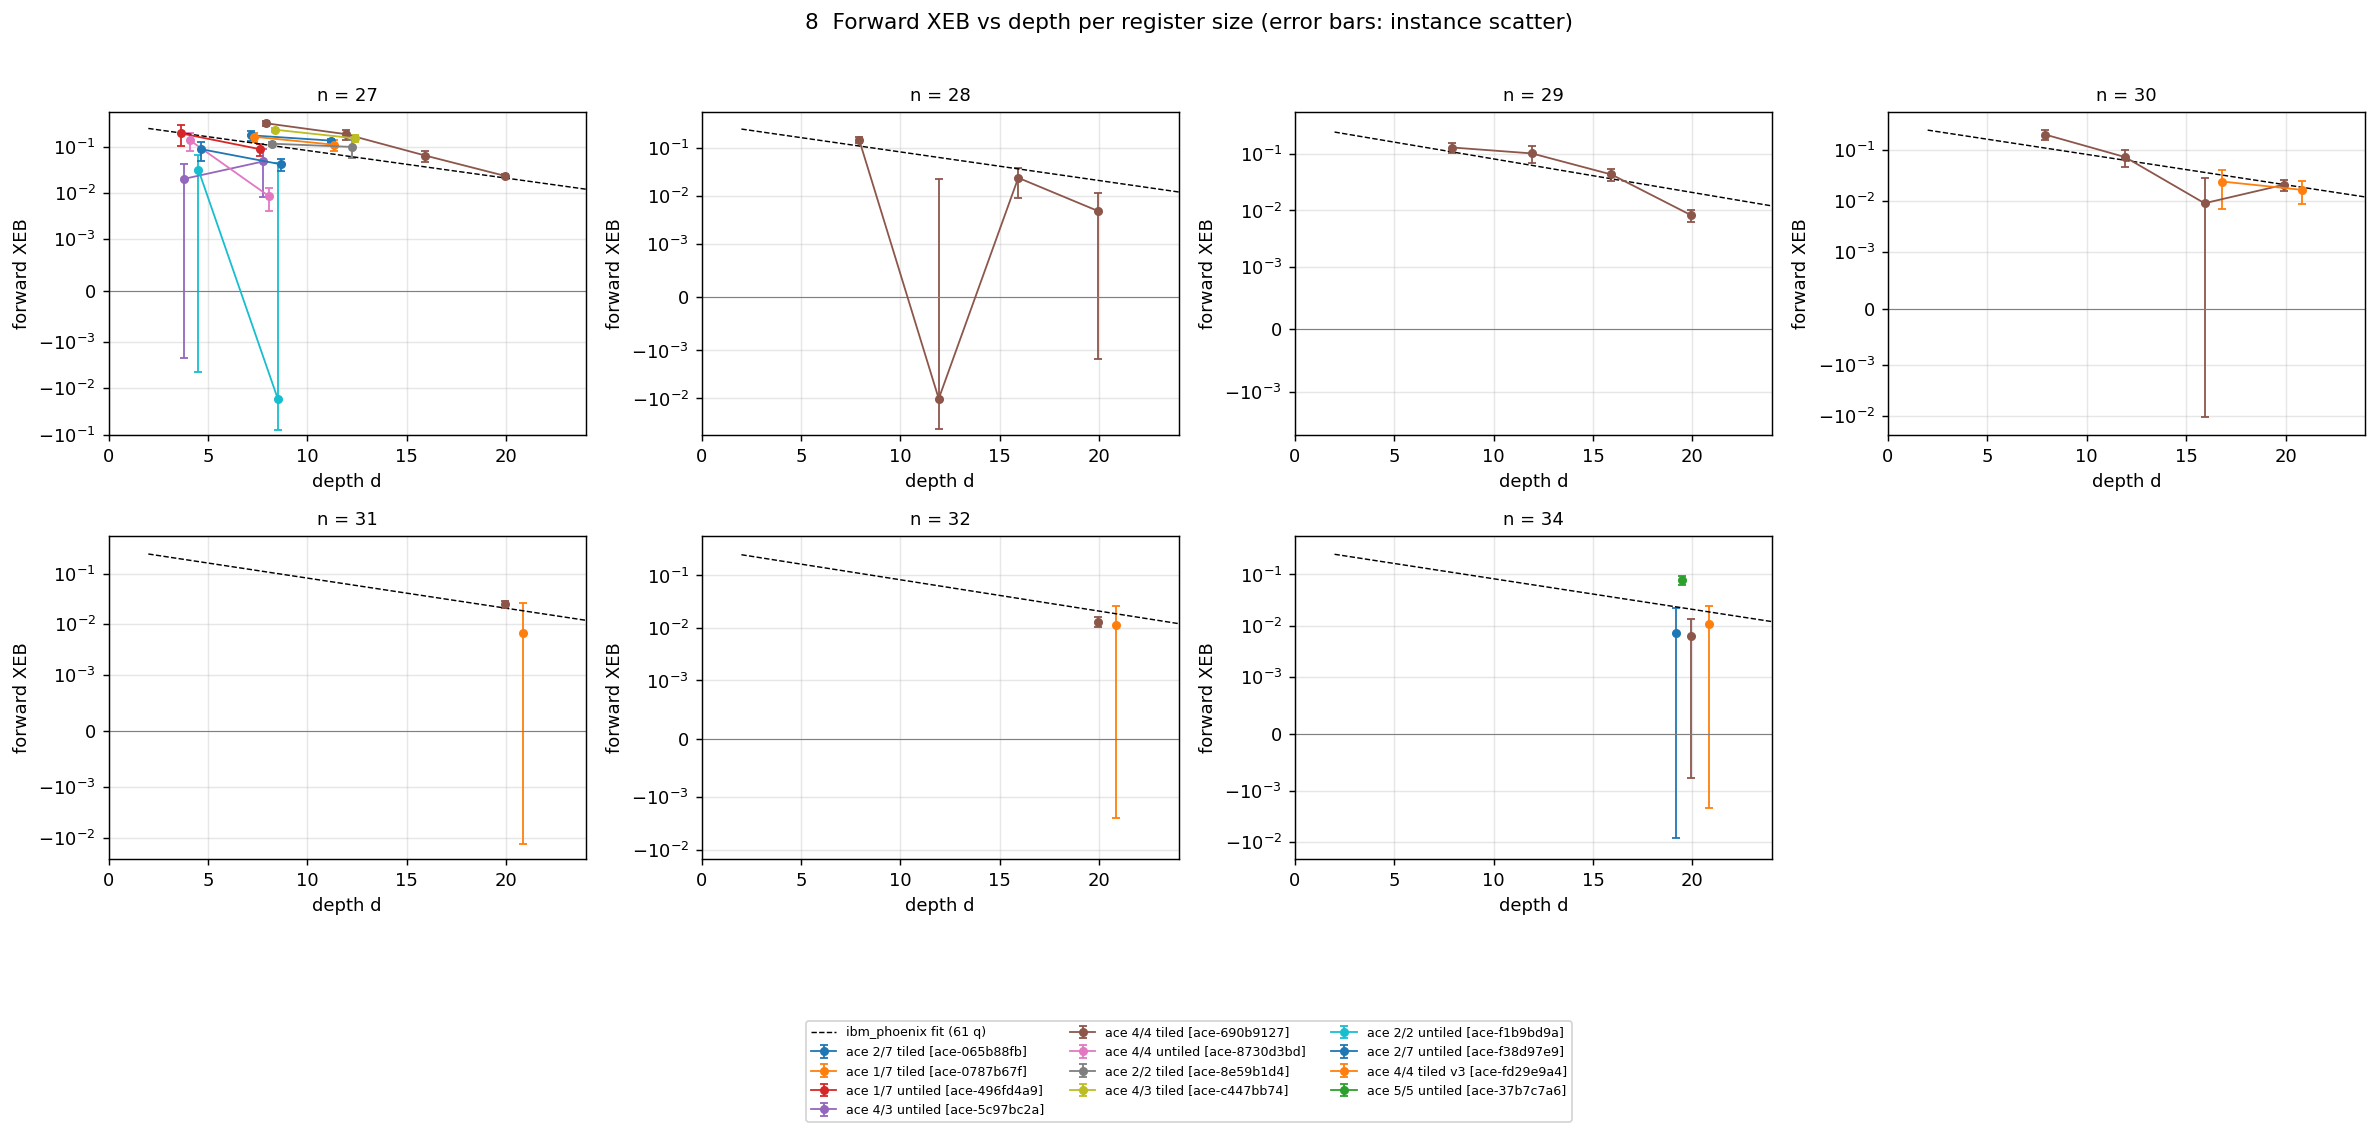


=== 9_fxn.png ===


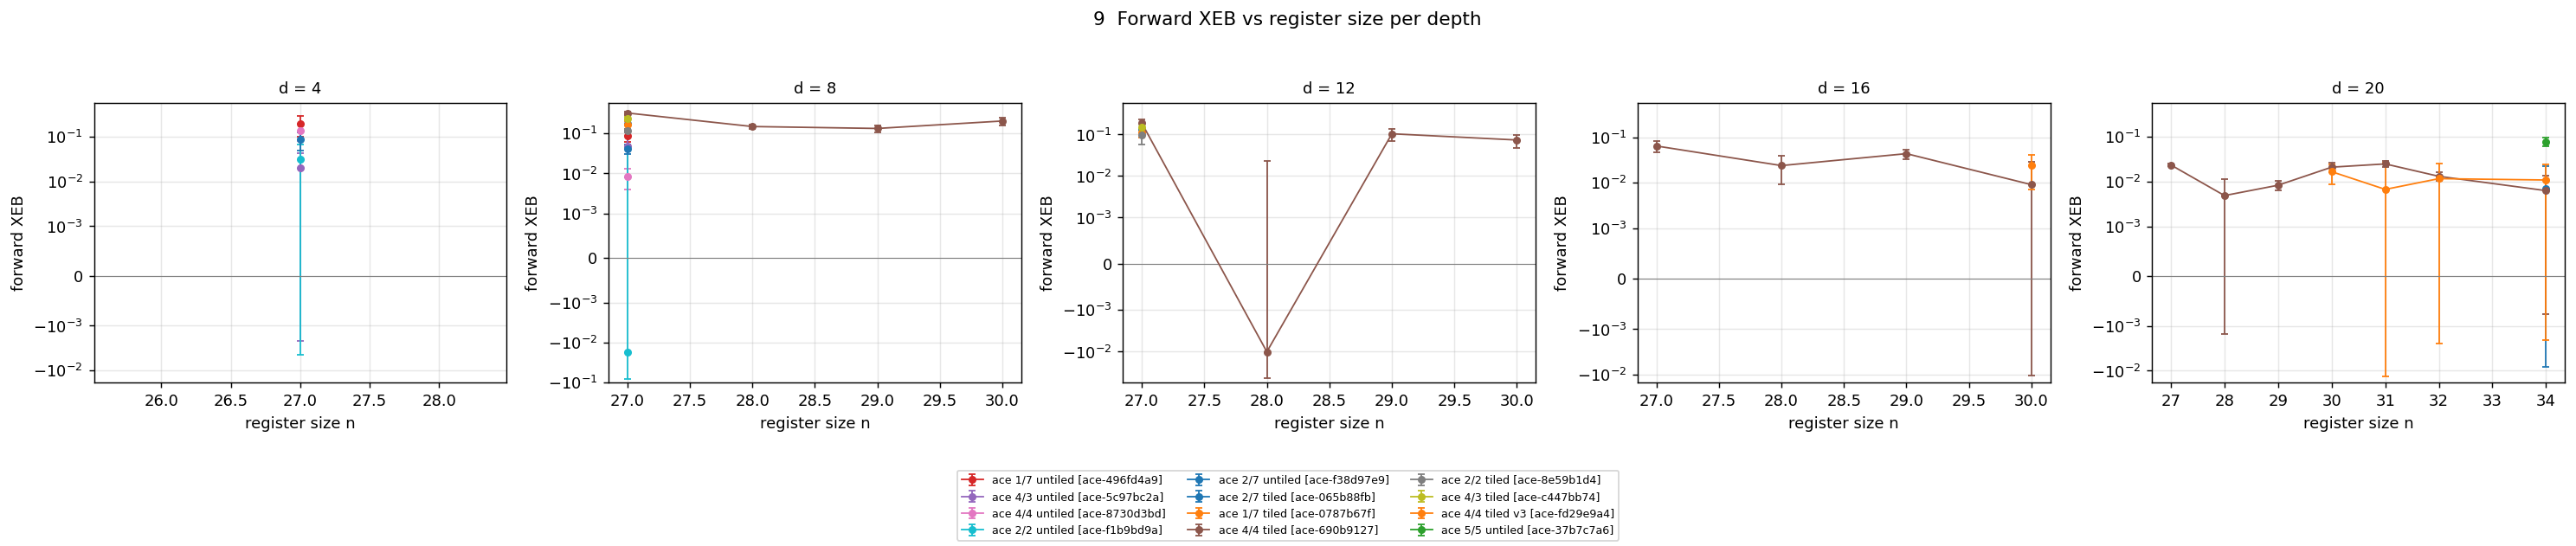


=== 10_fxb.png ===


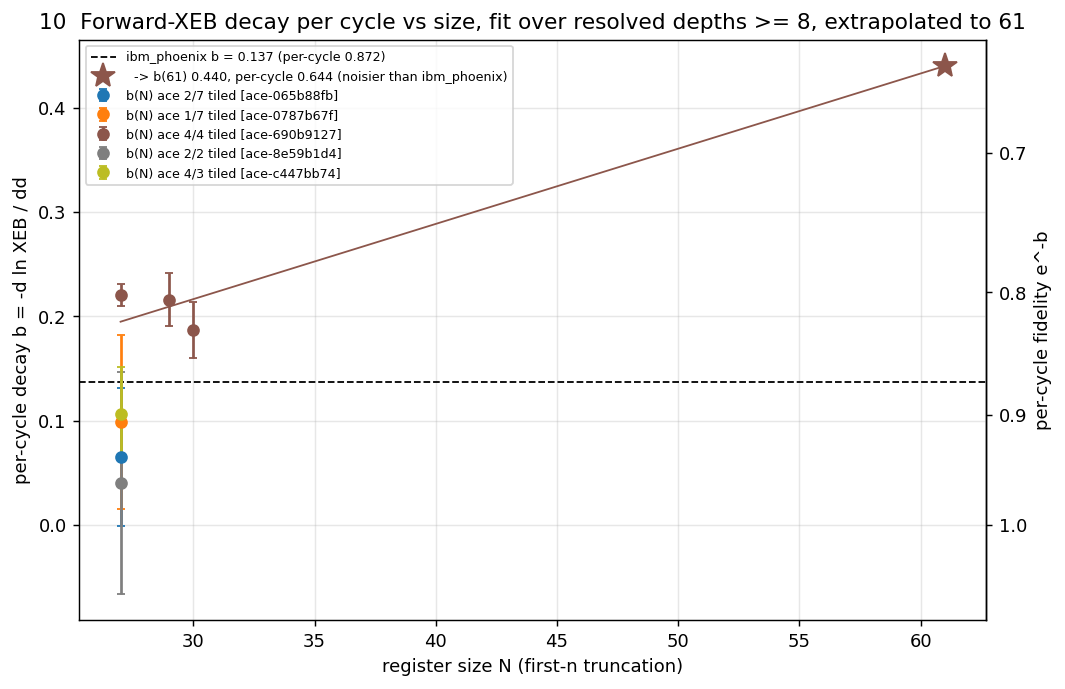


=== 11_fxp.png ===


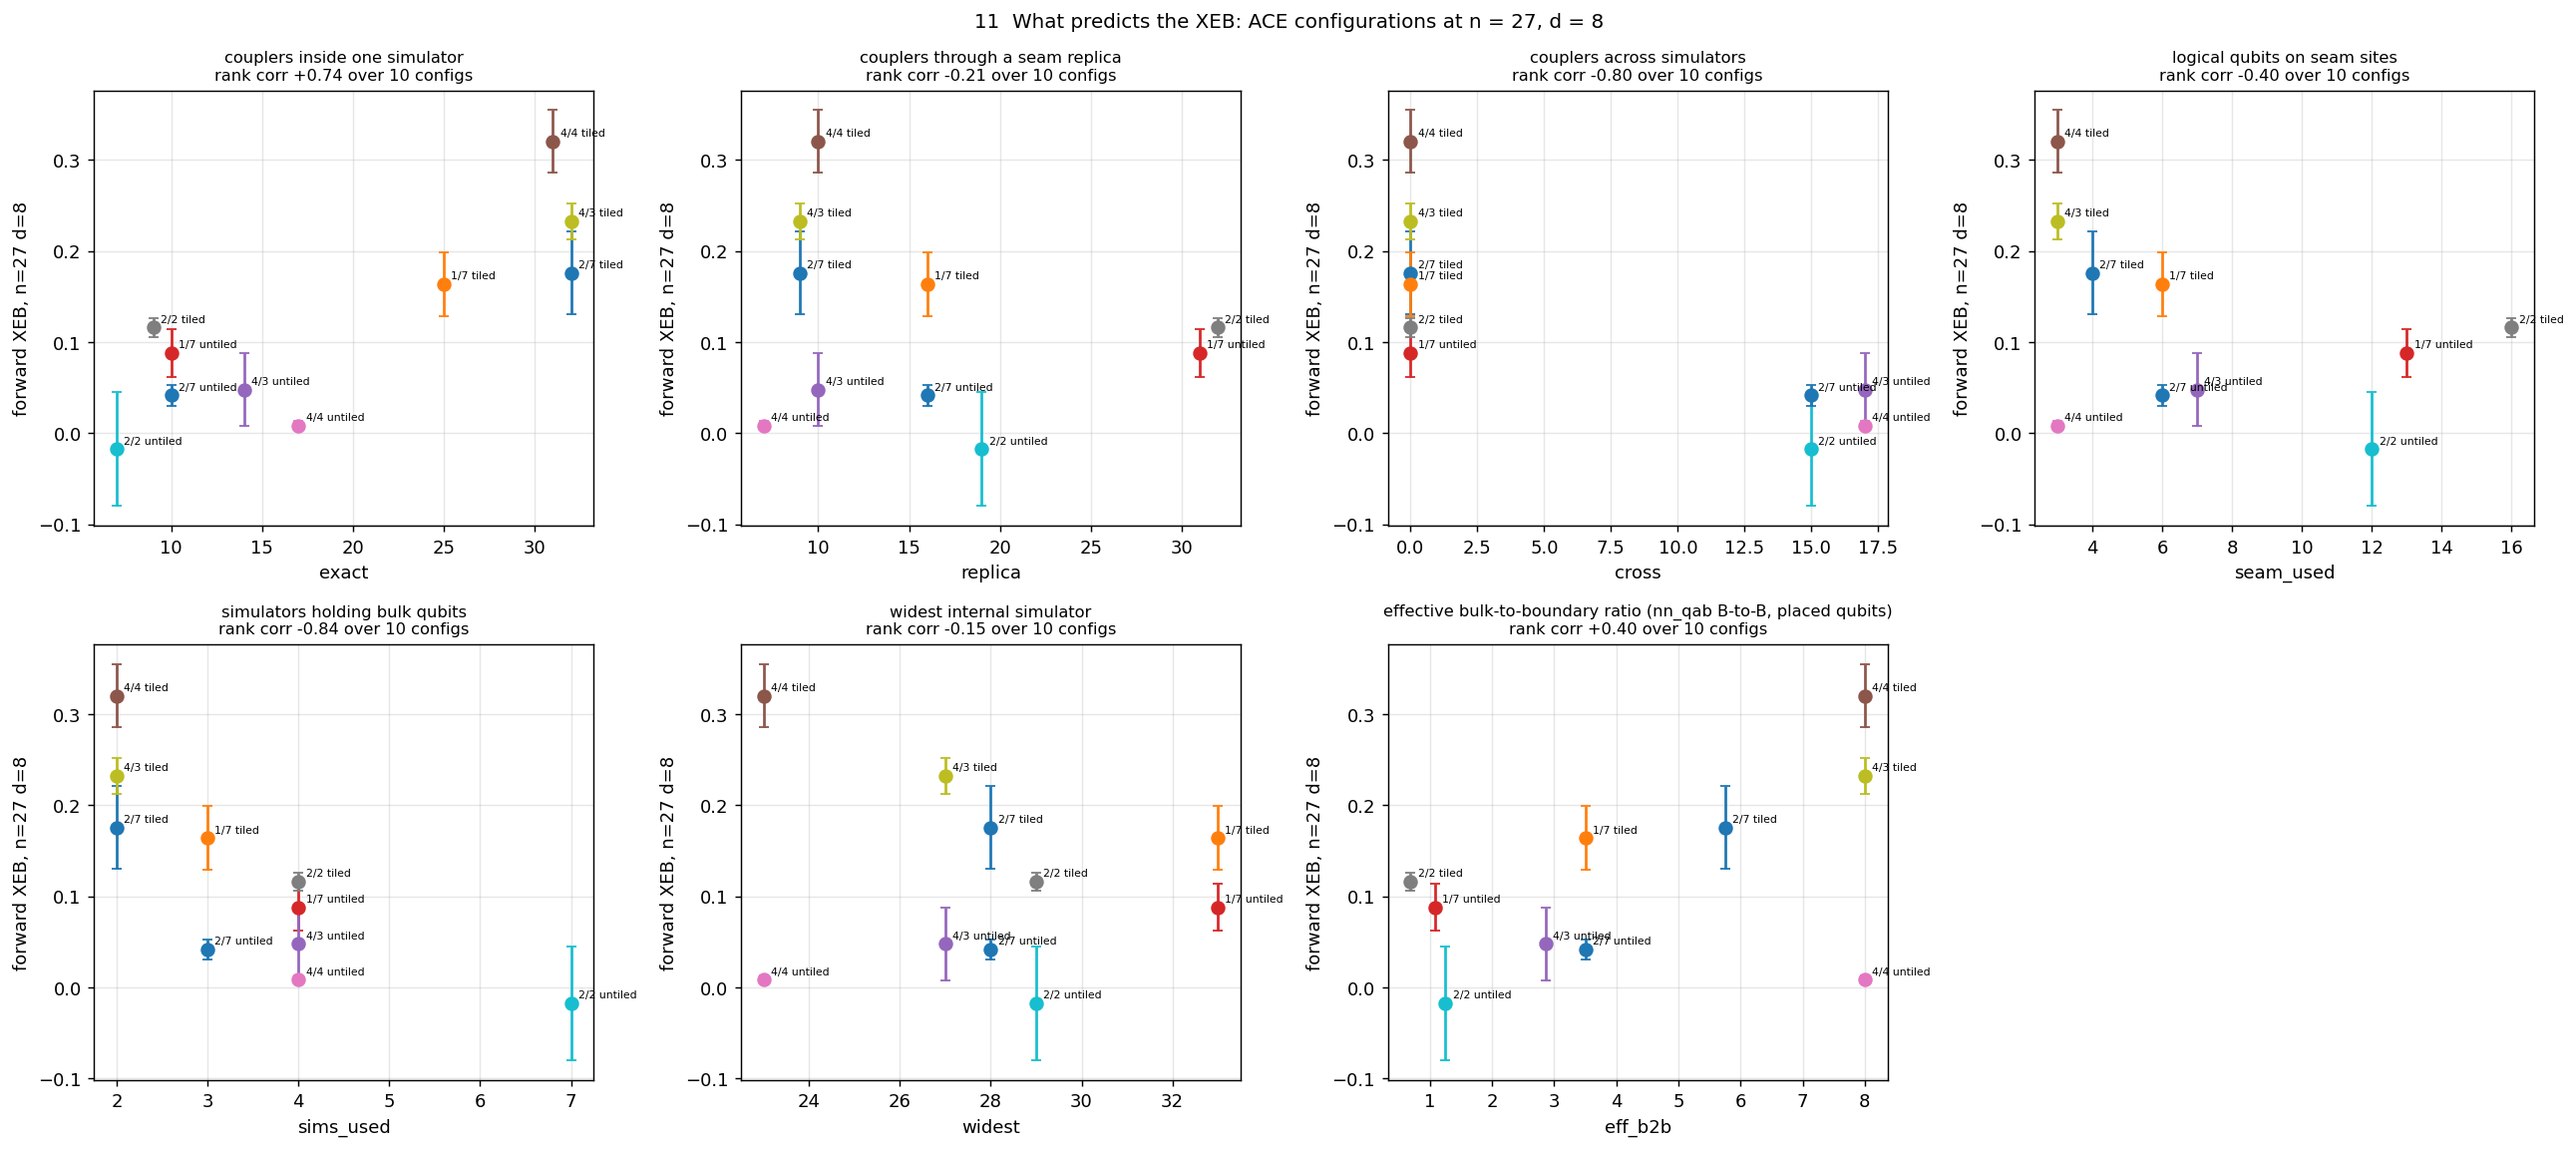


=== 12_hm.png ===


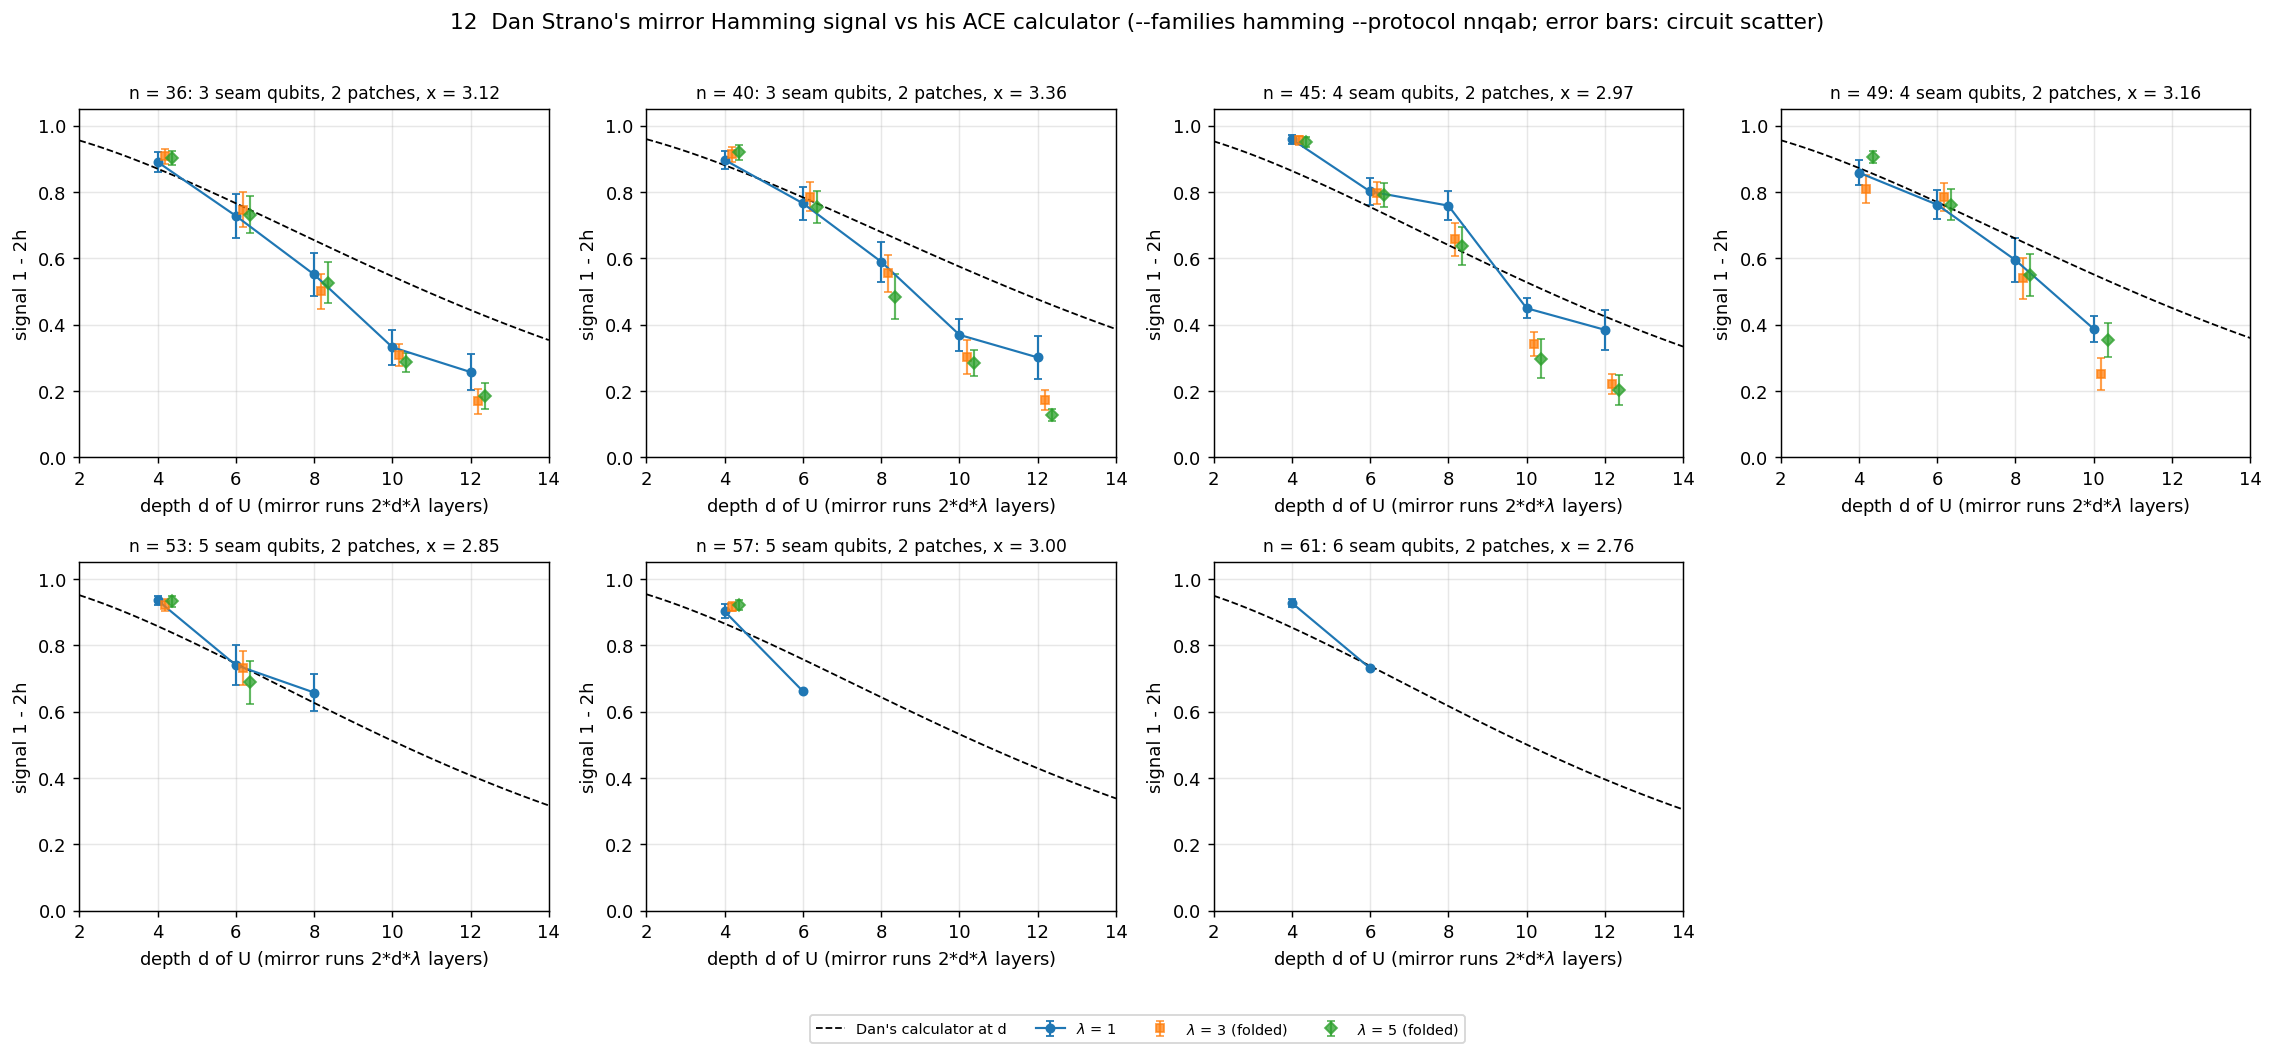


=== 13_hmr.png ===


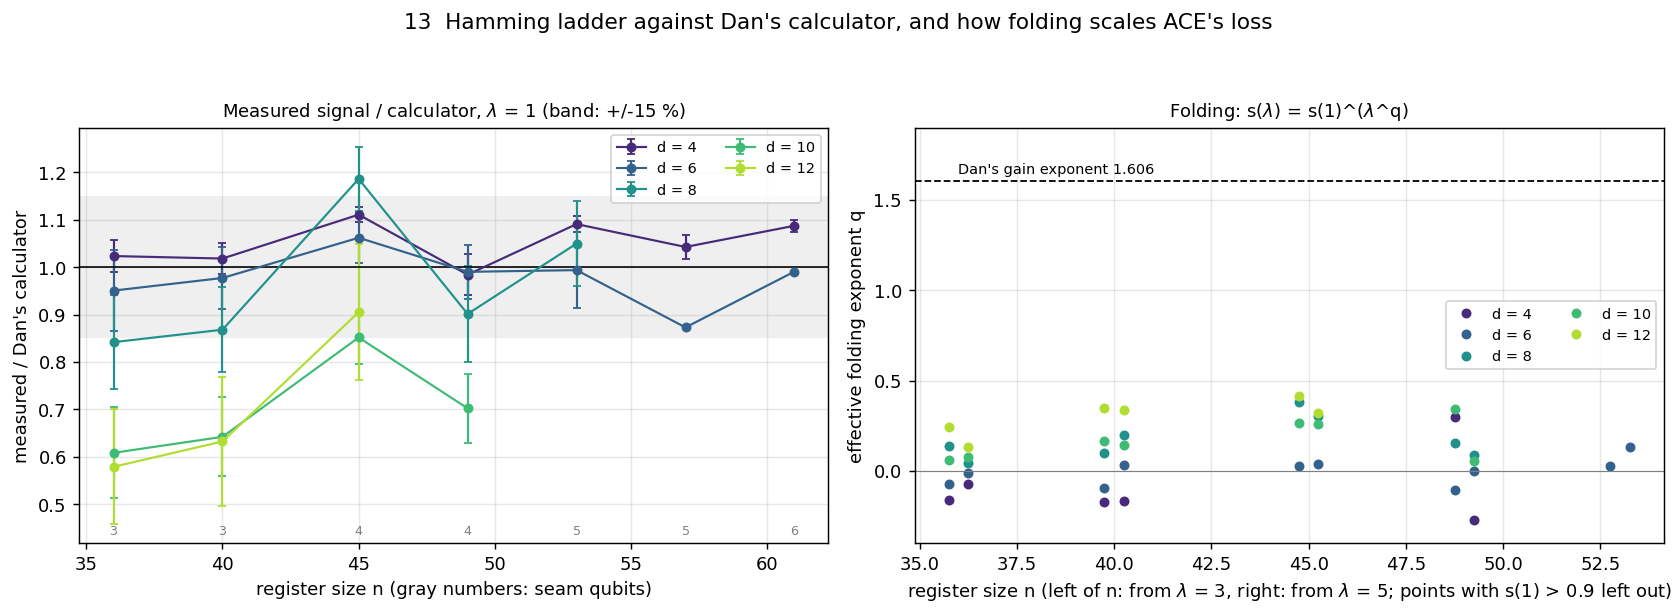

In [12]:
import tarfile
from IPython.display import Image, display

tar_path = Path("../nighthawk/rcs-nighthawk/nighthawk.tar.gz").resolve()
extract_dir = Path("measured_runs")
plots_dir = Path("plots_measured").resolve()
plots_dir.mkdir(exist_ok=True)

if not (extract_dir / "nighthawk").is_dir():
    extract_dir.mkdir(exist_ok=True)
    with tarfile.open(tar_path, "r:gz") as tf:
        if hasattr(tarfile, "data_filter"):      # Python >= 3.12 (and backports): refuse unsafe members
            tf.extractall(extract_dir, filter="data")
        else:
            tf.extractall(extract_dir)

graph_py = Path("nighthawk_graph.py").resolve()
run_cwd = extract_dir / "nighthawk"

run_logged(["python3", str(graph_py), "--table", str(plots_dir / "harvest.csv")], cwd=run_cwd)
run_logged(["python3", str(graph_py), "--save", str(plots_dir)], cwd=run_cwd)

for img_path in sorted(plots_dir.glob("*.png"), key=lambda p: int(p.name.split("_")[0])):
    print(f"\n=== {img_path.name} ===")
    display(Image(filename=str(img_path)))
